# H2O isotherms on Na-EMT and K-EMT
Processes the FTIR spectra recorded during stepwise H2O dosing on Na-EMT and K-EMT. For each sample, the baseline is corrected, the CH stretching band is integrated and its area is plotted against the equivalent pressure to give an adsorption isotherm.

### Setup
Imports the libraries, sets the Matplotlib defaults (live SVG text, Segoe UI font, label and tick sizes, resolution) and defines three helpers: `save_area_sheet` writes one or several tables to an Excel sheet, `add_minor_ticks` adds minor ticks and removes the top and right axes, and `find_linear_range` returns the number of points before saturation. It also sets the `data` folder path.

In [1]:
import spectrochempy as scp
import numpy as np
import matplotlib.pyplot as plt
import os
from pathlib import Path
from scipy import stats
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator
from openpyxl.utils import get_column_letter
from openpyxl.styles import Font
import re
from scipy.signal import find_peaks

mpl.rcParams.update({
    "svg.fonttype": "none",
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI"],
    "axes.unicode_minus": True,
    "axes.labelsize": 20,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "figure.dpi": 150,
    "savefig.dpi": 300,
})


def save_area_sheet(tables, sheet_name, path, gap=1):
    """Write one table, or several side by side, to a named sheet of an Excel workbook.

    tables: a DataFrame, or a dict {label: DataFrame}. With a dict, each table gets a
            bold label above it and the tables are separated by `gap` empty columns.
    """
    path = Path(path)
    mode = "a" if path.exists() else "w"
    kwargs = {"if_sheet_exists": "replace"} if mode == "a" else {}

    labelled = isinstance(tables, dict)
    if not labelled:
        tables = {None: tables}

    parts, starts, col = [], {}, 1
    for label, t in tables.items():
        if parts and gap:
            spacer = {" " * (len(parts) + 1): [""] * len(t)}        # unique blank header
            parts.append(pd.DataFrame(spacer))
            col += gap
        starts[label] = col
        parts.append(t.reset_index(drop=True))
        col += t.shape[1]
    combined = pd.concat(parts, axis=1)

    with pd.ExcelWriter(path, engine="openpyxl", mode=mode, **kwargs) as writer:
        combined.to_excel(writer, sheet_name=sheet_name, index=False,
                          startrow=1 if labelled else 0)
        ws = writer.sheets[sheet_name]

        if labelled:
            for label, c in starts.items():
                ws.cell(row=1, column=c, value=label).font = Font(bold=True, size=12)

        for i in range(combined.shape[1]):
            colvals = combined.iloc[:, i]
            width = max(len(str(combined.columns[i])), *(len(str(v)) for v in colvals)) + 2
            ws.column_dimensions[get_column_letter(i + 1)].width = width



def add_minor_ticks(ax=None, nx=4, ny=4):
    ax = ax or plt.gca()
    ax.xaxis.set_minor_locator(AutoMinorLocator(nx))
    ax.yaxis.set_minor_locator(AutoMinorLocator(ny))
    ax.tick_params(which="both", direction="out", top=False, right=False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


def find_linear_range(x, y, frac=0.5, n_ref=3, min_points=3, consecutive=1):
    """Return n = number of points before saturation.

    Local slope s_i = dy/dx between points i and i+1. The reference slope s0 is
    the median of the first n_ref local slopes. A step counts as saturated if
    s_i < frac * s0. The linear range ends at the first run of `consecutive`
    saturated steps.
    """
    s = np.diff(y) / np.diff(x)
    s0 = np.median(s[:n_ref])
    sat = s < frac * s0
    n = len(y)
    for i in range(len(sat) - consecutive + 1):
        if sat[i:i + consecutive].all():
            n = i + 1                    # points 0..i are kept
            break
    return max(n, min_points), s, s0


UNIT_TO_PA = {"torr": 133.322, "mbar": 100.0, "pa": 1.0}
pattern = re.compile(
    r"N(\d+)(?:[\s_\-]*(?:P(?:eq)?)?[\s_\-]*=|[\s_\-]+)\s*(\d+(?:[.,]\d+)?)\s*(torr|mbar|pa)?",
    re.IGNORECASE)

def pressures_from_filenames(folder, ext="*.SPA", default_unit="torr"):
    """Return (file names, pressures in Pa), ordered by the step number N<k> in the name.
    If a name has no unit, torr is assumed."""
    rows = []
    for f in Path(folder).glob(ext):
        m = pattern.search(f.stem)
        if m is None:
            raise ValueError(f"No pressure found in: {f.name}")
        step = int(m.group(1))
        value = float(m.group(2).replace(",", "."))
        unit = (m.group(3) or default_unit).lower()
        rows.append((step, f.name, value * UNIT_TO_PA[unit], unit))

    rows.sort(key=lambda r: r[0])
    steps = [r[0] for r in rows]
    assert len(set(steps)) == len(steps), f"Duplicate step numbers: {steps}"
    for r in rows:
        print(f"N{r[0]:<3d} {r[2]:10.2f} Pa   (unit used: {r[3]})")
    return [r[1] for r in rows], np.array([r[2] for r in rows])

current_directory = os.path.abspath('')
datapath = Path(current_directory, 'data')

### Load the spectra
Reads the Na-EMT and K-EMT isotherm spectra from the data folder into `D_Na` and `D_K`, and creates the output folder for the figures.

In [2]:
data_Na_old = Path(datapath, "Na-EMT V2/H2O 01092026/Isotherm")
D_Na_old = scp.read(data_Na_old)
data_Na_new = Path(datapath, "Na-EMT V2/H2O 02102026/Isotherm")
D_Na_new = scp.read(data_Na_new)
data_K_old = Path(datapath, "K-EMT-V2/H2O 23092026/Isotherm")
D_K_old = scp.read(data_K_old)
data_K_new = Path(datapath, "K-EMT-V2/H2O 28092026/Isotherm")
D_K_new = scp.read(data_K_new)


outputpath = Path(current_directory, 'output/H2O/isotherm')
outputpath.mkdir(parents=True, exist_ok=True)

<IPython.core.display.Javascript object>

### Label the spectra
Replaces the y axis with the acquisition order (0, 1, 2, ...), so that each spectrum has a simple number.

In [3]:
n_Na_old = D_Na_old.shape[0]  # number of spectra (y dimension)
n_K_old = D_K_old.shape[0]  # number of spectra (y dimension)
n_Na_new = D_Na_new.shape[0]  # number of spectra (y dimension)
n_K_new = D_K_new.shape[0]  # number of spectra (y dimension)

# integers 0, 1, 2, ... in acquisition order
D_Na_old.y = scp.Coord(np.arange(n_Na_old), title="spectrum number")
print(D_Na_old.y)

D_Na_new.y = scp.Coord(np.arange(n_Na_new), title="spectrum number")
print(D_Na_new.y)

D_K_old.y = scp.Coord(np.arange(n_K_old), title="spectrum number")
print(D_K_old.y)

D_K_new.y = scp.Coord(np.arange(n_K_new), title="spectrum number")
print(D_K_new.y)

Coord: [float64] unitless (size: 21)
Coord: [float64] unitless (size: 20)
Coord: [float64] unitless (size: 11)
Coord: [float64] unitless (size: 23)


### Raw spectra and select the spectral regions
Plots the full spectra of both samples and select the regions of interest

<Axes: title={'center': 'K-EMT new H2O bending 1800-1500 cm$^{-1}$'}, xlabel='wavenumbers $\\mathrm{/\\ \\mathrm{cm}^{-1}}$', ylabel='absorbance $\\mathrm{/\\ \\mathrm{a.u.}}$'>

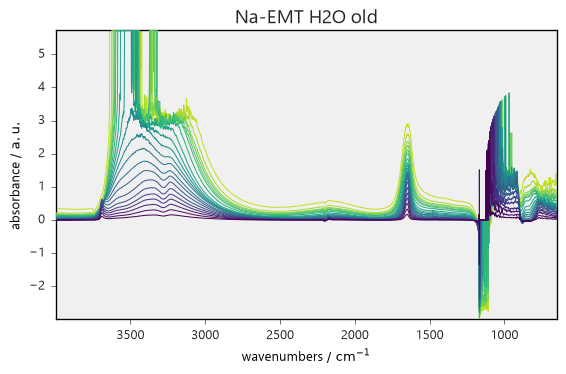

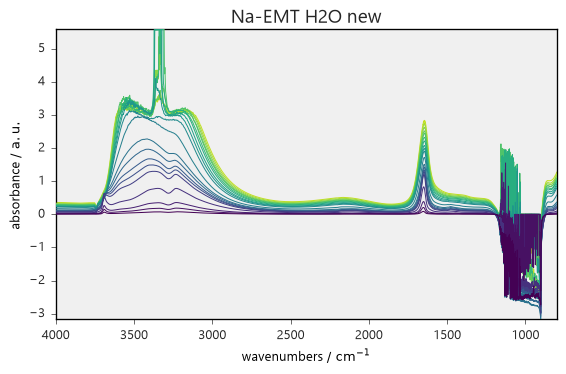

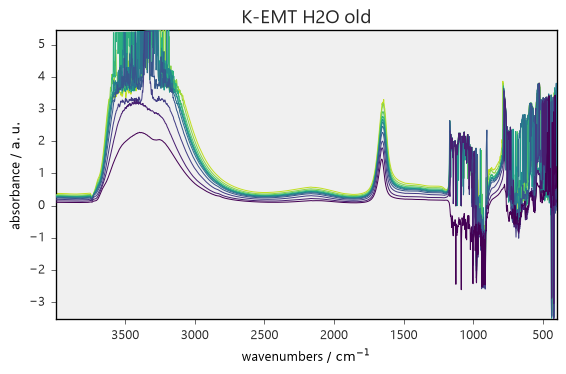

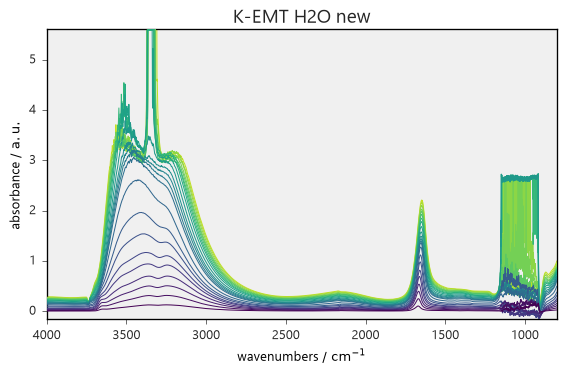

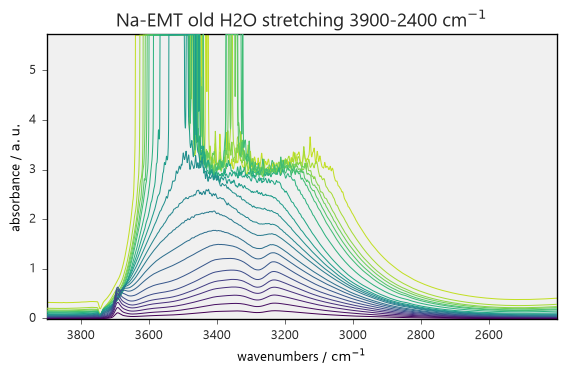

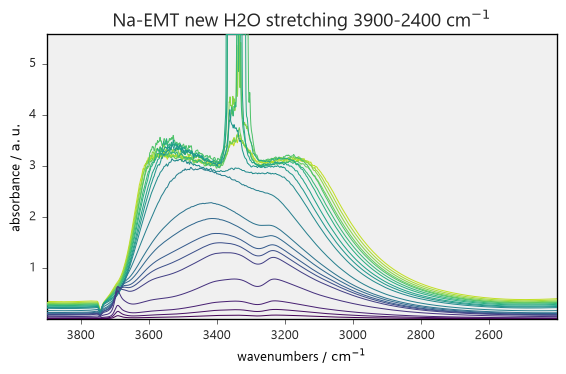

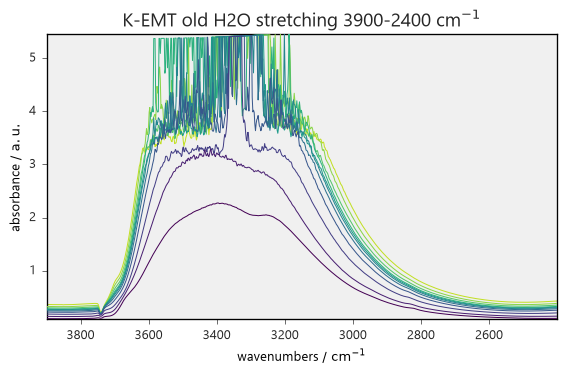

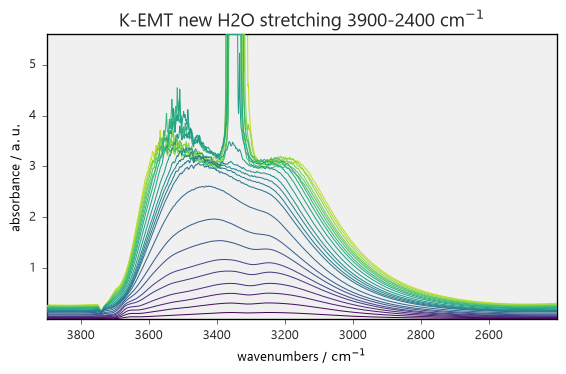

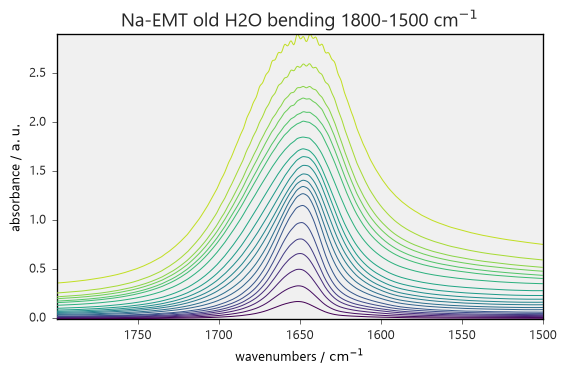

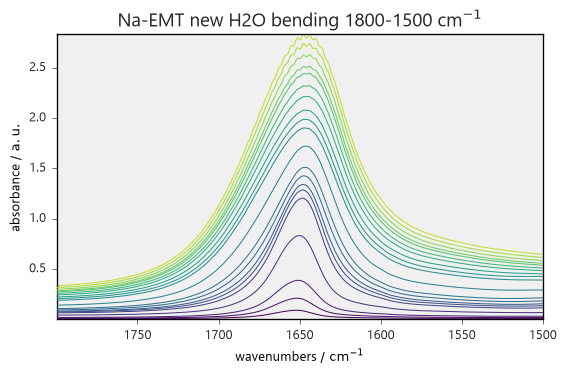

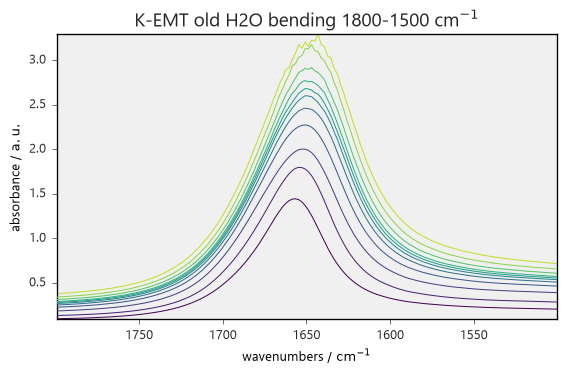

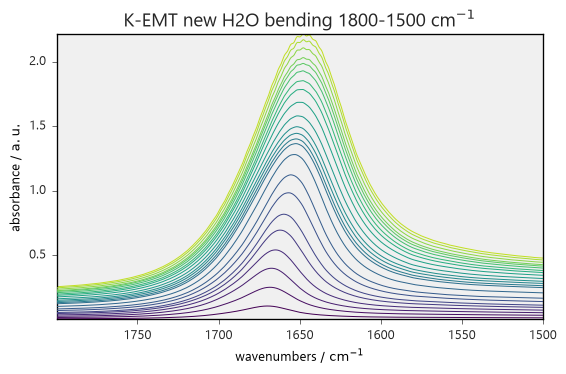

In [4]:
D_Na_old.plot(title='Na-EMT H2O old')
D_Na_new.plot(title='Na-EMT H2O new')
D_K_old.plot(title='K-EMT H2O old')
D_K_new.plot(title='K-EMT H2O new')

D_Na_old_stretching = D_Na_old[:, 3900.:2400.]
D_Na_new_stretching = D_Na_new[:, 3900.:2400.]
D_K_old_stretching = D_K_old[:, 3900.:2400.]
D_K_new_stretching = D_K_new[:, 3900.:2400.]
D_Na_old_stretching.plot(title='Na-EMT old H2O stretching 3900-2400 cm$^{-1}$')
D_Na_new_stretching.plot(title='Na-EMT new H2O stretching 3900-2400 cm$^{-1}$')
D_K_old_stretching.plot(title='K-EMT old H2O stretching 3900-2400 cm$^{-1}$')
D_K_new_stretching.plot(title='K-EMT new H2O stretching 3900-2400 cm$^{-1}$')
D_Na_old_bending = D_Na_old[:, 1800.:1500.]
D_Na_new_bending = D_Na_new[:, 1800.:1500.]
D_K_old_bending = D_K_old[:, 1800.:1500.]
D_K_new_bending = D_K_new[:, 1800.:1500.]
D_Na_old_bending.plot(title='Na-EMT old H2O bending 1800-1500 cm$^{-1}$')
D_Na_new_bending.plot(title='Na-EMT new H2O bending 1800-1500 cm$^{-1}$')
D_K_old_bending.plot(title='K-EMT old H2O bending 1800-1500 cm$^{-1}$')
D_K_new_bending.plot(title='K-EMT new H2O bending 1800-1500 cm$^{-1}$')

### Baseline of the bending region
Fits a linear baseline to the bending region of each sample, using the anchor ranges set in the cell, and plots the corrected spectra with their baselines.


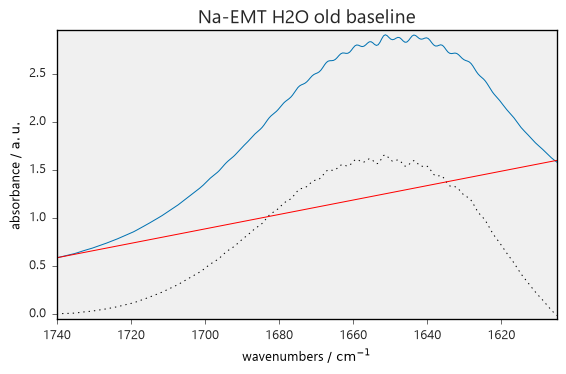

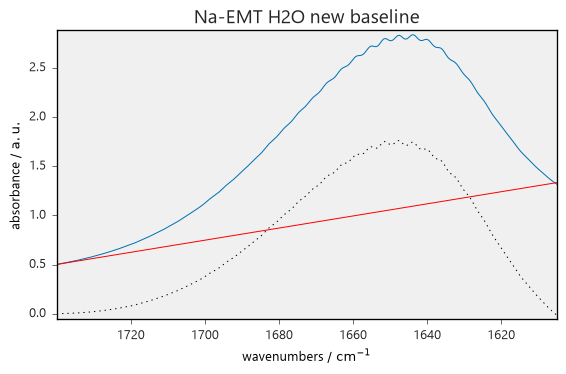

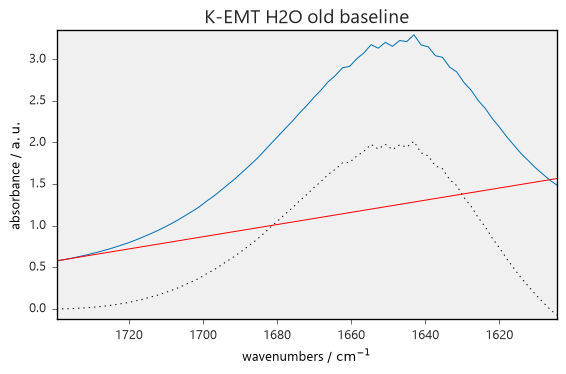

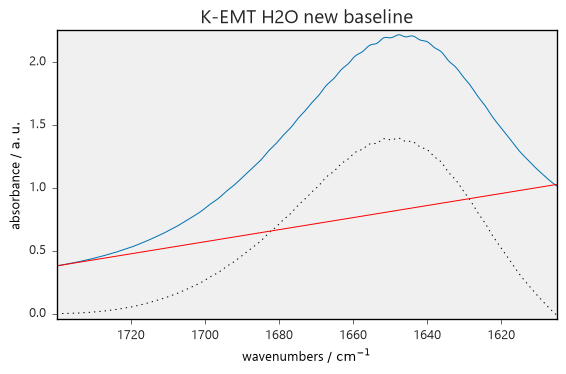

In [5]:
blc = scp.Baseline()
blc.multivariate = False
blc.model = 'polynomial'
blc.order = 1

_ = blc.fit(D_Na_old_bending[:, 1740.: 1605.])
D_Na_old_bending_corrected = blc.corrected
baseline = blc.baseline
_ = D_Na_old_bending[-1].plot(title='Na-EMT H2O old baseline')
_ = D_Na_old_bending_corrected[-1].plot(clear=False, color="black", ls=":")
_ = baseline[-1].plot(clear=False, color="red", ls="-")

_ = blc.fit(D_Na_new_bending[:, 1740.: 1605.])
D_Na_new_bending_corrected = blc.corrected
baseline = blc.baseline
_ = D_Na_new_bending[-1].plot(title='Na-EMT H2O new baseline')
_ = D_Na_new_bending_corrected[-1].plot(clear=False, color="black", ls=":")
_ = baseline[-1].plot(clear=False, color="red", ls="-")

#blc.snip_width = 50
_ = blc.fit(D_K_old_bending[:, 1740.: 1605.])
D_K_old_bending_corrected = blc.corrected
baseline = blc.baseline
_ = D_K_old_bending[-1].plot(title='K-EMT H2O old baseline')
_ = D_K_old_bending_corrected[-1].plot(clear=False, color="black", ls=":")
_ = baseline[-1].plot(clear=False, color="red", ls="-")

_ = blc.fit(D_K_new_bending[:, 1740.: 1605.])
D_K_new_bending_corrected = blc.corrected
baseline = blc.baseline
_ = D_K_new_bending[-1].plot(title='K-EMT H2O new baseline')
_ = D_K_new_bending_corrected[-1].plot(clear=False, color="black", ls=":")
_ = baseline[-1].plot(clear=False, color="red", ls="-")

### Na-EMT bending peaks
Plots the baseline-corrected bending region and labels the peaks found in the last (highest-dose) spectrum. The figure is saved as SVG.

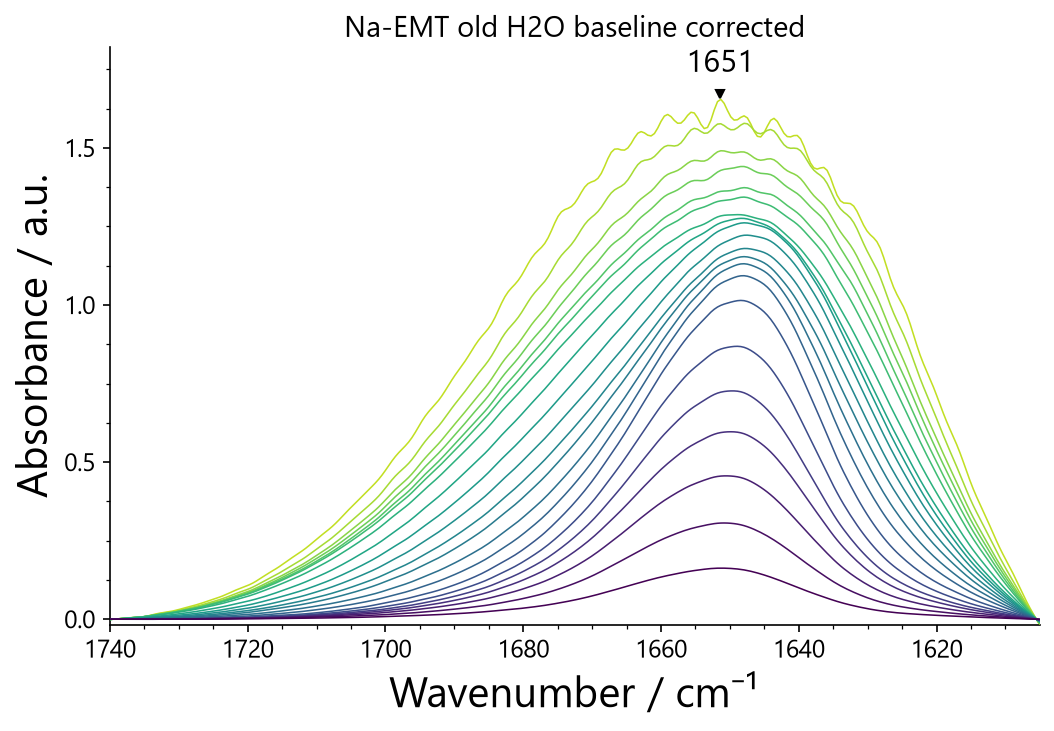

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
_ = D_Na_old_bending_corrected.plot(ax=ax, title="Na-EMT old H2O baseline corrected")

spectrum = D_Na_old_bending_corrected[-1]
peaks, props = spectrum.find_peaks(distance="5 cm^-1", prominence=0.1)

xs = np.asarray(peaks.x.data, dtype=float)
ys = np.asarray(peaks.data, dtype=float)

ax.plot(xs, ys + 0.01*ys, "v", color="black", markersize=4)
for x, y in zip(xs, ys):
    ax.annotate(f"{x:.0f}", (x, y), xytext=(0, 10), textcoords="offset points", rotation=0, va="bottom",
                ha="center", fontsize=15)

ax.set_ylim(np.min(D_Na_old_bending_corrected.data), np.max(D_Na_old_bending_corrected.data) + 0.1*np.max(D_Na_old_bending_corrected.data))
ax.set_xlabel("Wavenumber / cm⁻¹")
ax.set_ylabel("Absorbance / a.u.")
add_minor_ticks(ax)

fig.savefig(outputpath / "Na-EMT_old_H2O_corrected.svg", format="svg", bbox_inches="tight")

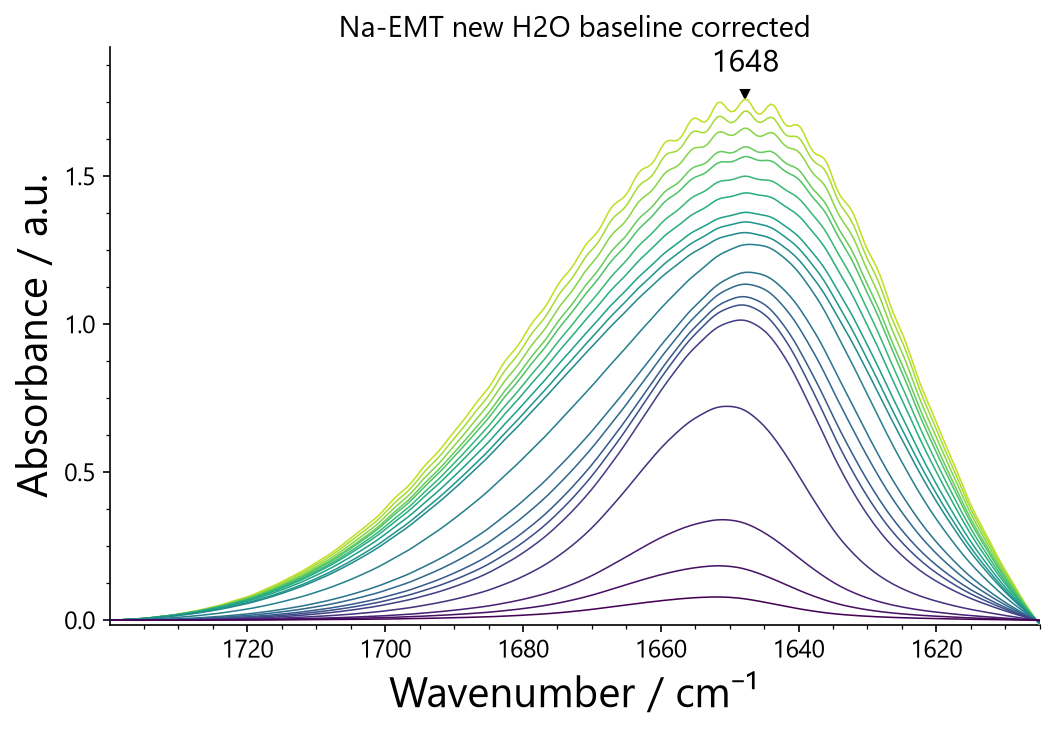

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
_ = D_Na_new_bending_corrected.plot(ax=ax, title="Na-EMT new H2O baseline corrected")

spectrum = D_Na_new_bending_corrected[-1]
peaks, props = spectrum.find_peaks(distance="5 cm^-1", prominence=0.1)

xs = np.asarray(peaks.x.data, dtype=float)
ys = np.asarray(peaks.data, dtype=float)

ax.plot(xs, ys + 0.01*ys, "v", color="black", markersize=4)
for x, y in zip(xs, ys):
    ax.annotate(f"{x:.0f}", (x, y), xytext=(0, 10), textcoords="offset points", rotation=0, va="bottom",
                ha="center", fontsize=15)

ax.set_ylim(np.min(D_Na_new_bending_corrected.data), np.max(D_Na_new_bending_corrected.data) + 0.1*np.max(D_Na_new_bending_corrected.data))
ax.set_xlabel("Wavenumber / cm⁻¹")
ax.set_ylabel("Absorbance / a.u.")
add_minor_ticks(ax)

fig.savefig(outputpath / "Na-EMT_new_H2O_corrected.svg", format="svg", bbox_inches="tight")

### K-EMT bending peaks
Same as above for K-EMT.

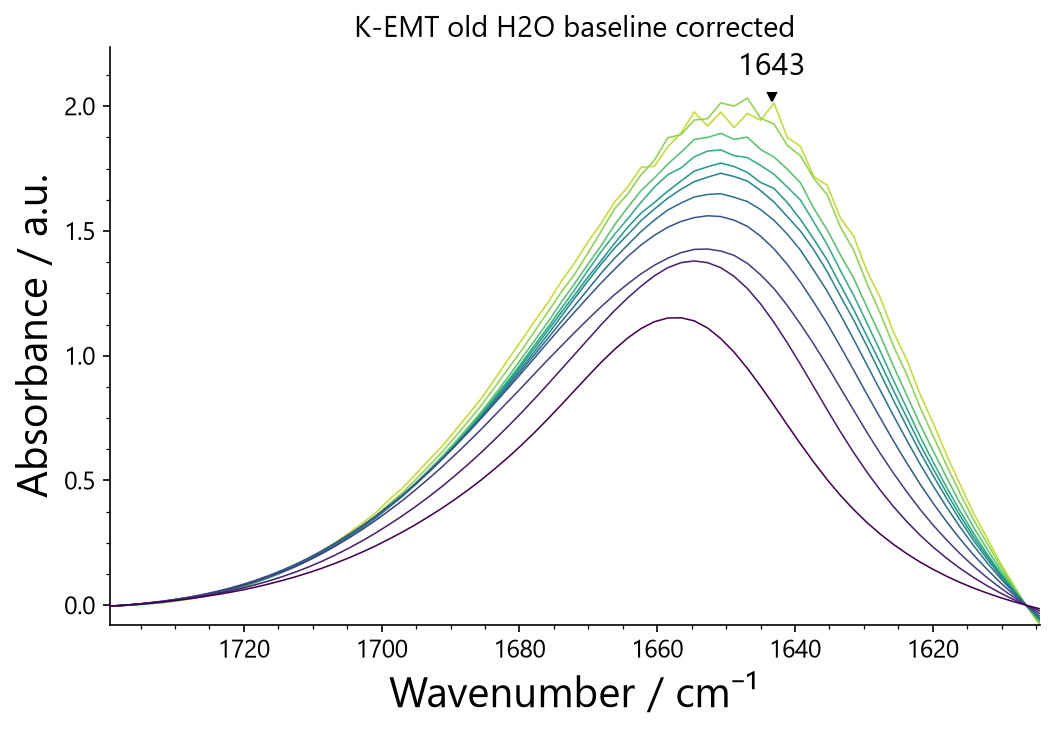

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
_ = D_K_old_bending_corrected.plot(ax=ax, title="K-EMT old H2O baseline corrected")

spectrum = D_K_old_bending_corrected[-1]
peaks, props = spectrum.find_peaks(distance="5 cm^-1", prominence=0.1)

xs = np.asarray(peaks.x.data, dtype=float)
ys = np.asarray(peaks.data, dtype=float)

ax.plot(xs, ys + 0.01*ys, "v", color="black", markersize=4)
for x, y in zip(xs, ys):
    ax.annotate(f"{x:.0f}", (x, y), xytext=(0, 10), textcoords="offset points", rotation=0, va="bottom",
                ha="center", fontsize=15)

ax.set_ylim(np.min(D_K_old_bending_corrected.data), np.max(D_K_old_bending_corrected.data) + 0.1*np.max(D_K_old_bending_corrected.data))
ax.set_xlabel("Wavenumber / cm⁻¹")
ax.set_ylabel("Absorbance / a.u.")
add_minor_ticks(ax)

fig.savefig(outputpath / "K-EMT_old_H2O_corrected.svg", format="svg", bbox_inches="tight")

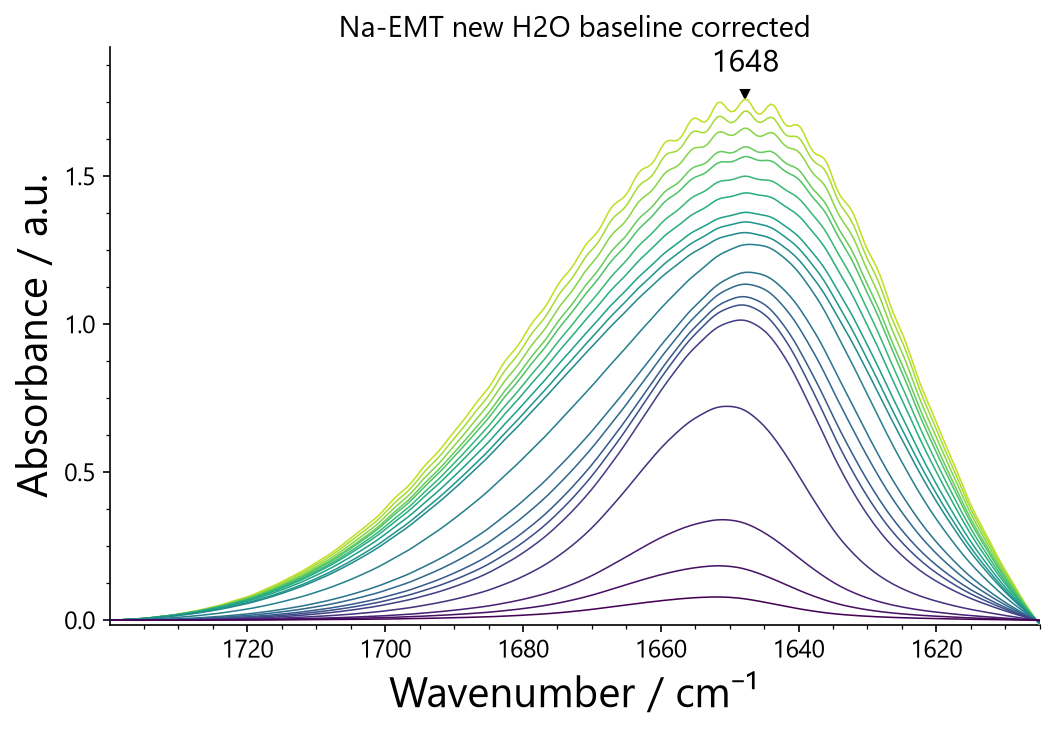

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
_ = D_Na_new_bending_corrected.plot(ax=ax, title="Na-EMT new H2O baseline corrected")

spectrum = D_Na_new_bending_corrected[-1]
peaks, props = spectrum.find_peaks(distance="5 cm^-1", prominence=0.1)

xs = np.asarray(peaks.x.data, dtype=float)
ys = np.asarray(peaks.data, dtype=float)

ax.plot(xs, ys + 0.01*ys, "v", color="black", markersize=4)
for x, y in zip(xs, ys):
    ax.annotate(f"{x:.0f}", (x, y), xytext=(0, 10), textcoords="offset points", rotation=0, va="bottom",
                ha="center", fontsize=15)

ax.set_ylim(np.min(D_Na_new_bending_corrected.data), np.max(D_Na_new_bending_corrected.data) + 0.1*np.max(D_Na_new_bending_corrected.data))
ax.set_xlabel("Wavenumber / cm⁻¹")
ax.set_ylabel("Absorbance / a.u.")
add_minor_ticks(ax)

fig.savefig(outputpath / "Na-EMT_new_H2O_corrected.svg", format="svg", bbox_inches="tight")

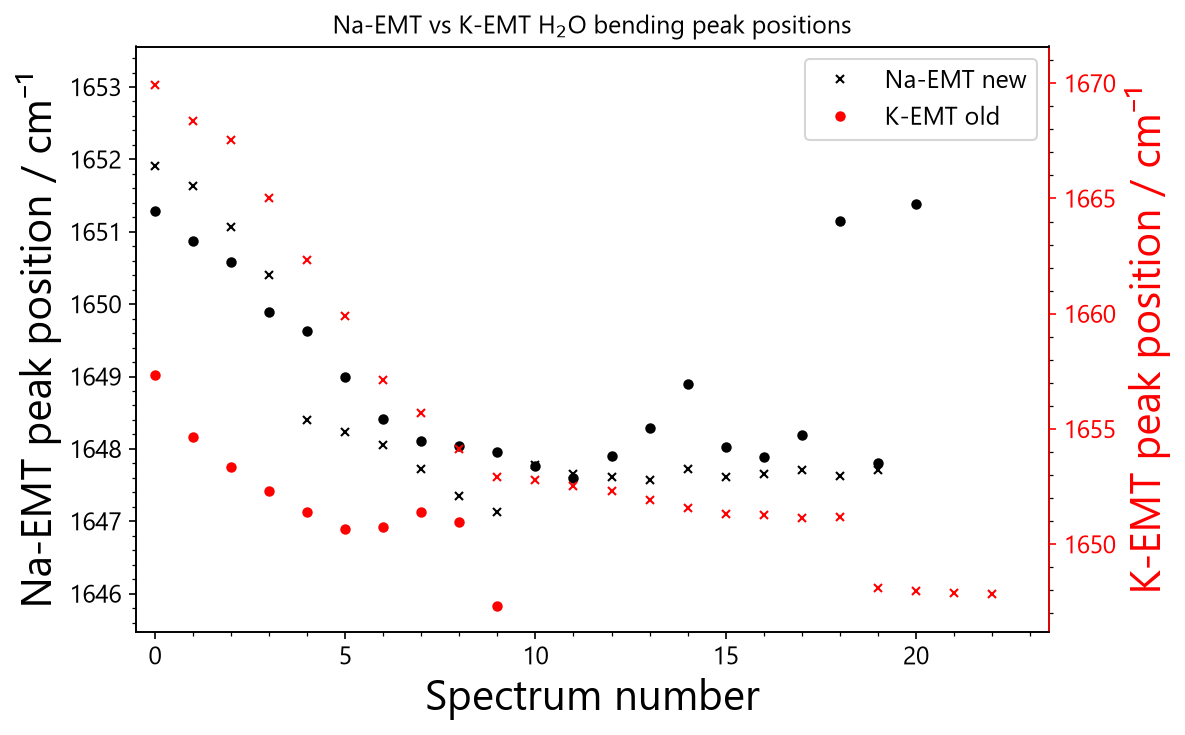

In [10]:
peaks_Na_old = []
for spectrum in D_Na_old_bending_corrected:
    peaks, props = spectrum.find_peaks(distance="5 cm^-1", prominence=0.1)
    peaks_Na_old.append(peaks.x.data)

peaks_Na_new = []
for spectrum in D_Na_new_bending_corrected:
    peaks, props = spectrum.find_peaks(distance="5 cm^-1", prominence=0.05)
    peaks_Na_new.append(peaks.x.data)

peaks_K_old = []
for spectrum in D_K_old_bending_corrected:
    peaks, props = spectrum.find_peaks(distance="5 cm^-1", prominence=0.1)
    peaks_K_old.append(peaks.x.data)

peaks_K_new = []
for spectrum in D_K_new_bending_corrected:
    peaks, props = spectrum.find_peaks(distance="5 cm^-1", prominence=0.05)
    peaks_K_new.append(peaks.x.data)

fig, ax = plt.subplots(figsize=(8, 5))
ax2 = ax.twinx()                                   # second y-axis, same x-axis

l1, = ax.plot(peaks_Na_old, marker="o", markersize=4, linestyle="", color="black", label="Na-EMT old")
l1, = ax.plot(peaks_Na_new, marker="x", markersize=4, linestyle="", color="black", label="Na-EMT new")
l2, = ax2.plot(peaks_K_old, marker="o", markersize=4, linestyle="", color="red", label="K-EMT old")
l3, = ax2.plot(peaks_K_new, marker="x", markersize=4, linestyle="", color="red", label="K-EMT new")

ax.set_xlabel("Spectrum number")
ax.set_xlim(-0.5, D_K_new.shape[0] + 0.5)
ax.set_ylim(np.min(peaks_Na_new) - 0.001*np.min(peaks_Na_new), np.max(peaks_Na_new) + 0.001*np.max(peaks_Na_new ))
ax2.set_ylim(np.min(peaks_K_new) - 0.001*np.min(peaks_K_new), np.max(peaks_K_new) + 0.001*np.max(peaks_K_new))
ax.set_ylabel("Na-EMT peak position / cm\u207b\u00b9", color="black")
ax2.set_ylabel("K-EMT peak position / cm\u207b\u00b9", color="red")
ax.tick_params(axis="y", colors="black")
ax2.tick_params(axis="y", colors="red")
ax.set_title("Na-EMT vs K-EMT H$_2$O bending peak positions")

ax.legend(handles=[l1, l2], loc="best")            # one legend for both axes
ax2.spines["right"].set_visible(True)              # add_minor_ticks hides the right spine
ax2.spines["right"].set_color("red")
ax.minorticks_on()
ax2.minorticks_on()
fig.tight_layout()

### Integrate the areas

In [11]:
area_Na_H2O_old = D_Na_old_bending_corrected.trapezoid(dim="x")
area_Na_H2O_new = D_Na_new_bending_corrected.trapezoid(dim="x")
area_K_H2O_old = D_K_old_bending_corrected.trapezoid(dim="x")
area_K_H2O_new = D_K_new_bending_corrected.trapezoid(dim="x")

### Na-EMT isotherm
Identifies the pressure from the spectra name and then converts the equivalent pressures to Pa and plots the bending secondary area against pressure. The figure is saved as SVG.

N1        24.40 Pa   (unit used: torr)
N2        26.26 Pa   (unit used: torr)
N3        28.26 Pa   (unit used: torr)
N4        29.86 Pa   (unit used: torr)
N5        31.73 Pa   (unit used: torr)
N6        33.46 Pa   (unit used: torr)
N7        34.80 Pa   (unit used: torr)
N8        36.26 Pa   (unit used: torr)
N9        37.60 Pa   (unit used: torr)
N10       41.60 Pa   (unit used: torr)
N11       45.20 Pa   (unit used: torr)
N12       47.86 Pa   (unit used: torr)
N13       51.06 Pa   (unit used: torr)
N14       57.86 Pa   (unit used: torr)
N15       94.79 Pa   (unit used: torr)
N16      214.38 Pa   (unit used: torr)
N17      395.30 Pa   (unit used: torr)
N18      642.61 Pa   (unit used: torr)
N19      981.25 Pa   (unit used: torr)
N20     1649.19 Pa   (unit used: torr)
N21     2266.47 Pa   (unit used: torr)
N1         0.00 Pa   (unit used: torr)
N2         0.00 Pa   (unit used: torr)
N3         0.00 Pa   (unit used: torr)
N5         0.13 Pa   (unit used: torr)
N8         0.53 Pa   (uni

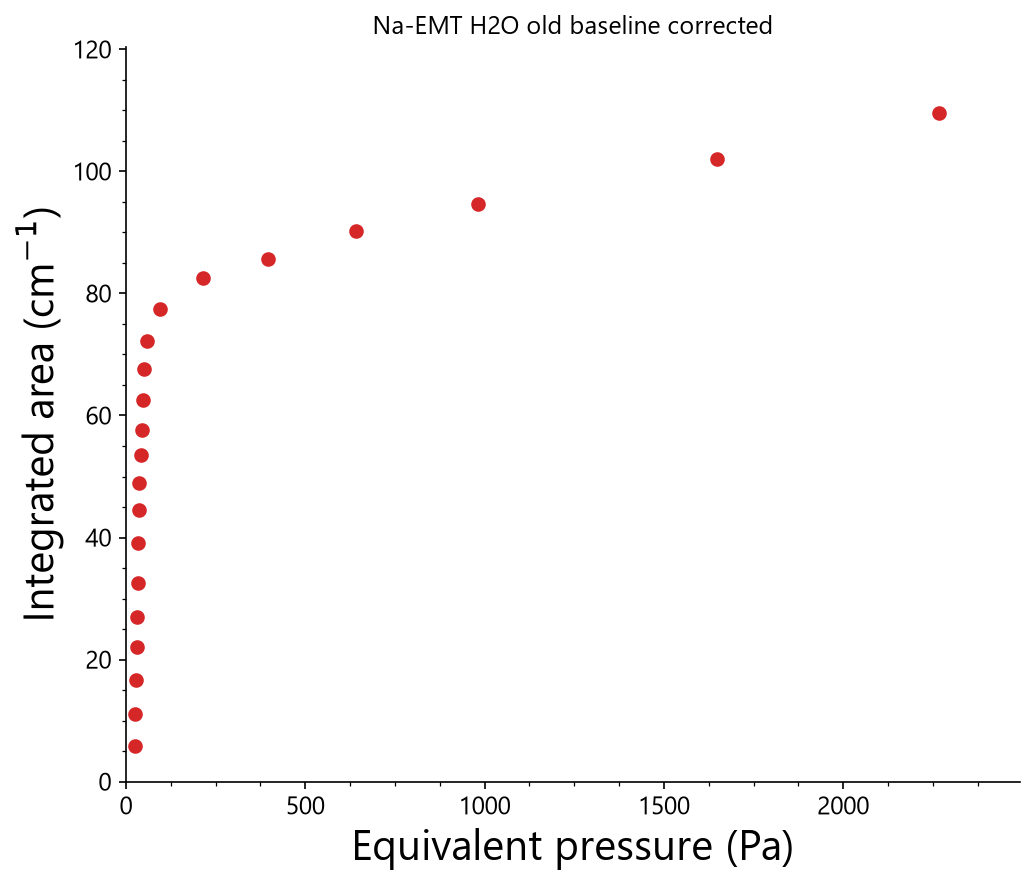

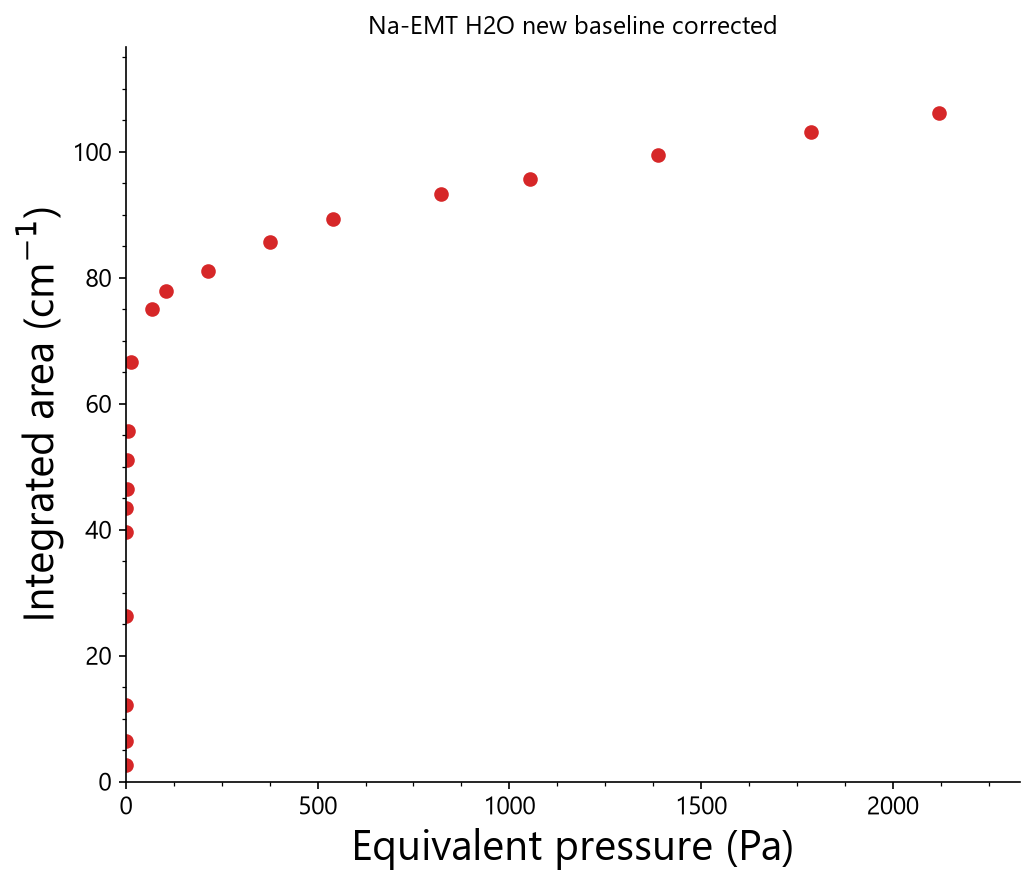

In [12]:
names_Na_old, x_Na_old = pressures_from_filenames(data_Na_old)
x_Na_old = x_Na_old[:len(area_Na_H2O_old.data)]  # truncate to match the number of spectra
y_Na_old = np.abs(np.asarray(area_Na_H2O_old.data)).ravel()

names_Na_new, x_Na_new = pressures_from_filenames(data_Na_new)
x_Na_new = x_Na_new[:len(area_Na_H2O_new.data)]  # truncate to match the number of spectra
y_Na_new = np.abs(np.asarray(area_Na_H2O_new.data)).ravel()

fig, ax1 = plt.subplots(1, 1, figsize=(7, 6))
ax1.plot(x_Na_old, y_Na_old, "o", color="C3")
ax1.set_ylabel(r"Integrated area (cm$^{-1}$)")
ax1.set_xlabel("Equivalent pressure (Pa)")
ax1.set_title(f"Na-EMT H2O old baseline corrected")
ax1.set_xlim(0, max(x_Na_old) + 0.1*max(x_Na_old))
ax1.set_ylim(0, max(y_Na_old) + 0.1*max(y_Na_old))
add_minor_ticks(ax1)
fig.tight_layout()
fig.savefig(outputpath / "Na-EMT-H2O_old_isotherm.svg", format="svg", bbox_inches="tight")
plt.show()

fig, ax1 = plt.subplots(1, 1, figsize=(7, 6))
ax1.plot(x_Na_new, y_Na_new, "o", color="C3")
ax1.set_ylabel(r"Integrated area (cm$^{-1}$)")
ax1.set_xlabel("Equivalent pressure (Pa)")
ax1.set_title(f"Na-EMT H2O new baseline corrected")
ax1.set_xlim(0, max(x_Na_new) + 0.1*max(x_Na_new))
ax1.set_ylim(0, max(y_Na_new) + 0.1*max(y_Na_new))
add_minor_ticks(ax1)
fig.tight_layout()
fig.savefig(outputpath / "Na-EMT-H2O_new _isotherm.svg", format="svg", bbox_inches="tight")
plt.show()

### K-EMT isotherm
Same as previous cell.


N1       152.60 Pa   (unit used: mbar)
N2       155.00 Pa   (unit used: mbar)
N3       173.20 Pa   (unit used: mbar)
N4       224.20 Pa   (unit used: mbar)
N5       322.50 Pa   (unit used: mbar)
N6       432.80 Pa   (unit used: mbar)
N7       509.00 Pa   (unit used: mbar)
N8       615.60 Pa   (unit used: mbar)
N9       944.00 Pa   (unit used: mbar)
N10     1550.00 Pa   (unit used: mbar)
N11     2260.00 Pa   (unit used: mbar)
N1         0.00 Pa   (unit used: torr)
N2         0.80 Pa   (unit used: torr)
N3         1.60 Pa   (unit used: torr)
N4         2.27 Pa   (unit used: torr)
N5         3.07 Pa   (unit used: torr)
N6         3.87 Pa   (unit used: torr)
N7         5.07 Pa   (unit used: torr)
N8         6.13 Pa   (unit used: torr)
N9        11.07 Pa   (unit used: torr)
N10       21.33 Pa   (unit used: torr)
N11       28.53 Pa   (unit used: torr)
N12       42.00 Pa   (unit used: torr)
N13       62.26 Pa   (unit used: torr)
N14      109.06 Pa   (unit used: torr)
N15      192.52 Pa   (uni

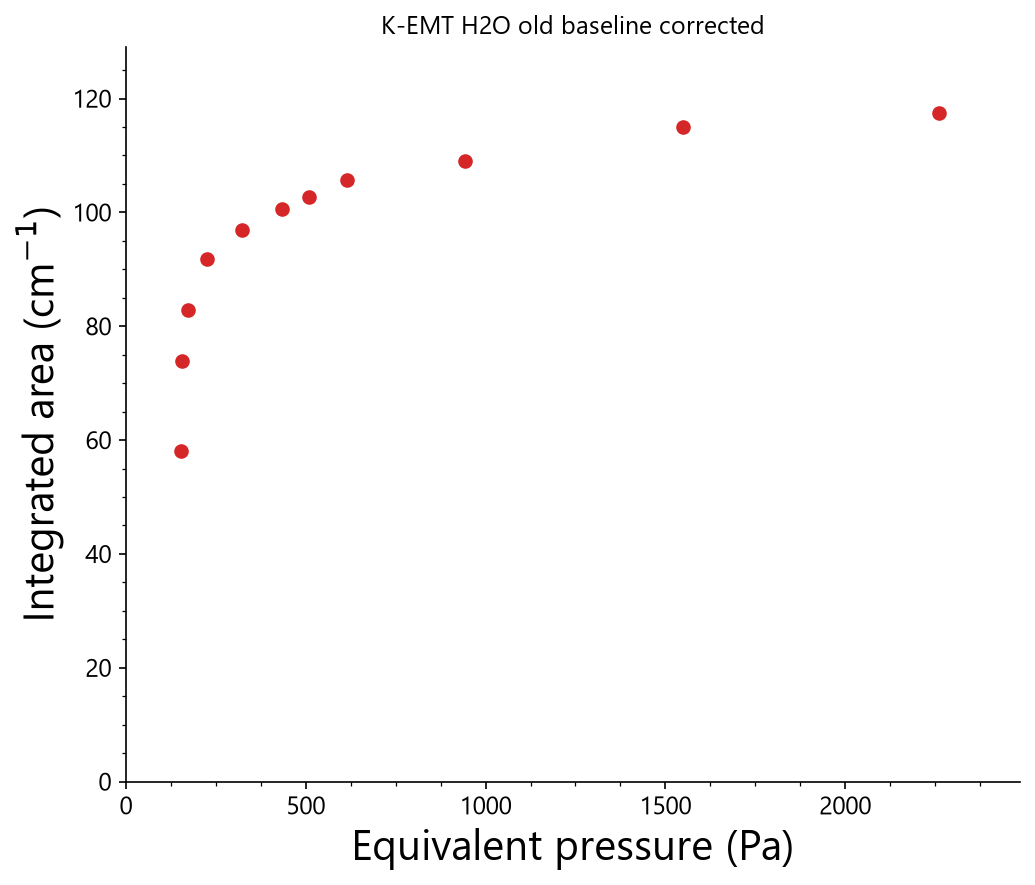

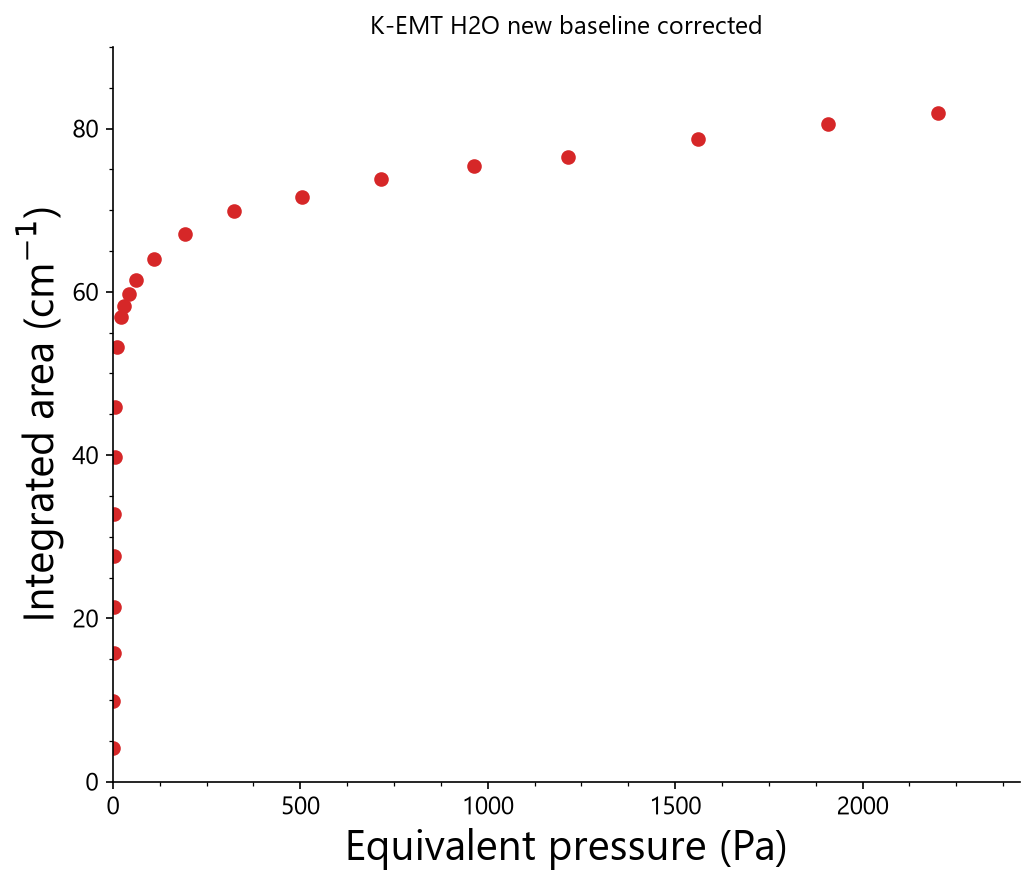

In [13]:
names_K_old, x_K_old = pressures_from_filenames(data_K_old)
x_K_old = x_K_old[:len(area_K_H2O_old.data)]  # truncate to match the number of spectra
y_K_old = np.abs(np.asarray(area_K_H2O_old.data)).ravel()

names_K_new, x_K_new = pressures_from_filenames(data_K_new)
x_K_new = x_K_new[:len(area_K_H2O_new.data)]  # truncate to match the number of spectra
y_K_new = np.abs(np.asarray(area_K_H2O_new.data)).ravel()

fig, ax1 = plt.subplots(1, 1, figsize=(7, 6))
ax1.plot(x_K_old, y_K_old, "o", color="C3")
ax1.set_ylabel(r"Integrated area (cm$^{-1}$)")
ax1.set_xlabel("Equivalent pressure (Pa)")
ax1.set_title(f"K-EMT H2O old baseline corrected")
ax1.set_xlim(0, max(x_K_old) + 0.1*max(x_K_old))
ax1.set_ylim(0, max(y_K_old) + 0.1*max(y_K_old))
add_minor_ticks(ax1)
fig.tight_layout()
fig.savefig(outputpath / "K-EMT-H2O_old_isotherm.svg", format="svg", bbox_inches="tight")
plt.show()

fig, ax1 = plt.subplots(1, 1, figsize=(7, 6))
ax1.plot(x_K_new, y_K_new, "o", color="C3")
ax1.set_ylabel(r"Integrated area (cm$^{-1}$)")
ax1.set_xlabel("Equivalent pressure (Pa)")
ax1.set_title(f"K-EMT H2O new baseline corrected")
ax1.set_xlim(0, max(x_K_new) + 0.1*max(x_K_new))
ax1.set_ylim(0, max(y_K_new) + 0.1*max(y_K_new))
add_minor_ticks(ax1)
fig.tight_layout()
fig.savefig(outputpath / "K-EMT-H2O_new _isotherm.svg", format="svg", bbox_inches="tight")
plt.show()

### Na-EMT vs K-EMT isotherms
Plots both isotherms on the same axes to compare the two samples. The x axis spans the full pressure range.

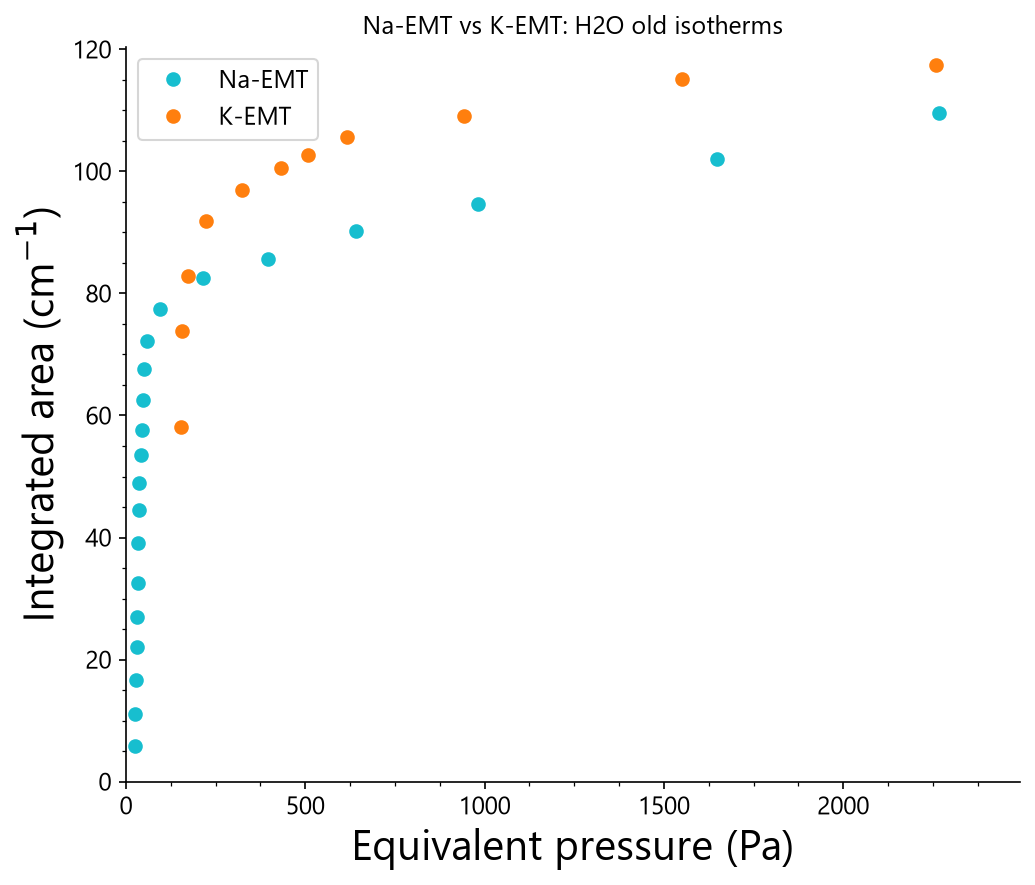

In [14]:
fig, ax = plt.subplots(1, 1, figsize=(7, 6))
ax.plot(x_Na_old, y_Na_old, "o", color="C9", label="Na-EMT")
ax.plot(x_K_old, y_K_old, "o", color="C1", label="K-EMT")
ax.set_ylabel(r"Integrated area (cm$^{-1}$)")
ax.set_xlabel("Equivalent pressure (Pa)")
ax.set_title(f"Na-EMT vs K-EMT: H2O old isotherms")
ax.set_xlim(0, max(x_Na_old) + 0.1*max(x_Na_old))
ax.set_ylim(0, max(y_Na_old) + 0.1*max(y_Na_old))
add_minor_ticks(ax)
ax.legend(loc="upper left")
add_minor_ticks(ax)
fig.tight_layout()
fig.savefig(outputpath / "Na-EMT_vs_K-EMT-H2O_old_isotherm.svg", format="svg", bbox_inches="tight")
plt.show()

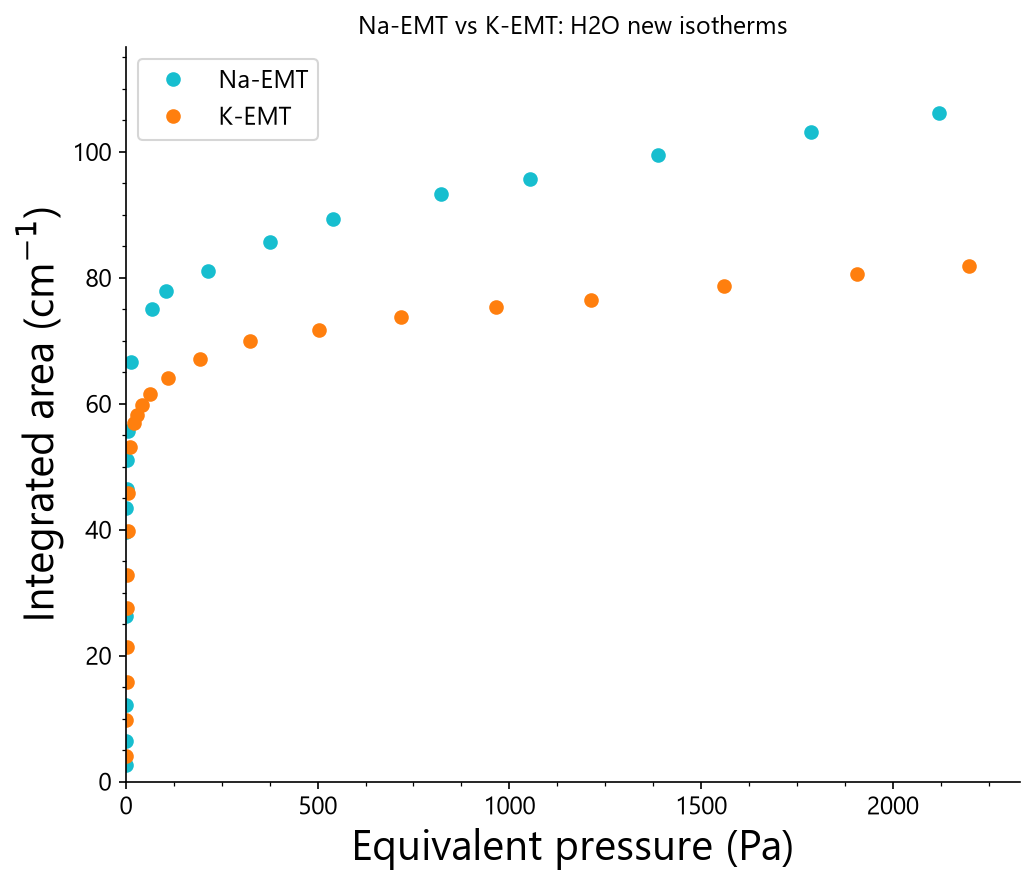

In [15]:
fig, ax = plt.subplots(1, 1, figsize=(7, 6))
ax.plot(x_Na_new, y_Na_new, "o", color="C9", label="Na-EMT")
ax.plot(x_K_new, y_K_new, "o", color="C1", label="K-EMT")
ax.set_ylabel(r"Integrated area (cm$^{-1}$)")
ax.set_xlabel("Equivalent pressure (Pa)")
ax.set_title(f"Na-EMT vs K-EMT: H2O new isotherms")
ax.set_xlim(0, max(x_Na_new) + 0.1*max(x_Na_new))
ax.set_ylim(0, max(y_Na_new) + 0.1*max(y_Na_new))
add_minor_ticks(ax)
ax.legend(loc="upper left")
add_minor_ticks(ax)
fig.tight_layout()
fig.savefig(outputpath / "Na-EMT_vs_K-EMT-H2O_new_isotherm.svg", format="svg", bbox_inches="tight")
plt.show()

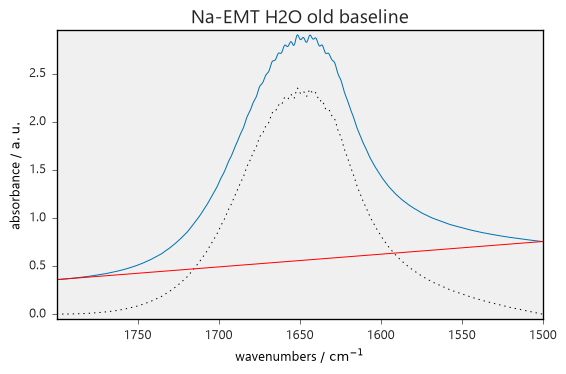

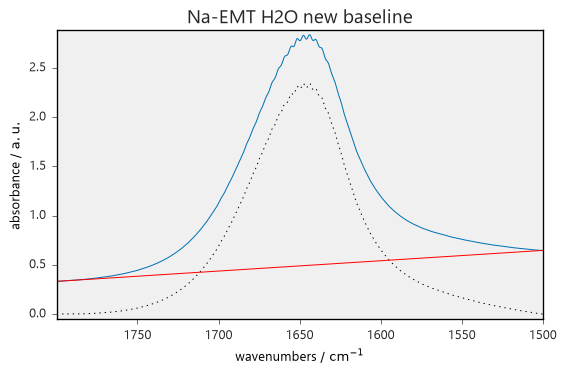

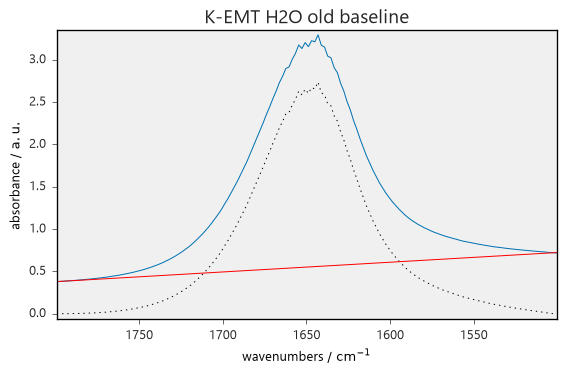

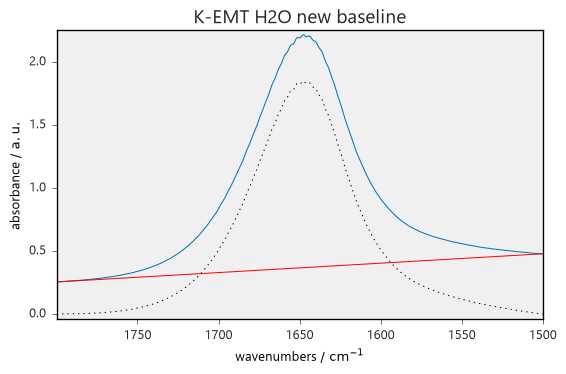

In [16]:
blc = scp.Baseline()
blc.multivariate = False
blc.model = 'polynomial'
blc.order = 1

_ = blc.fit(D_Na_old_bending)
D_Na_old_bending_corrected = blc.corrected
baseline = blc.baseline
_ = D_Na_old_bending[-1].plot(title='Na-EMT H2O old baseline')
_ = D_Na_old_bending_corrected[-1].plot(clear=False, color="black", ls=":")
_ = baseline[-1].plot(clear=False, color="red", ls="-")

_ = blc.fit(D_Na_new_bending)
D_Na_new_bending_corrected = blc.corrected
baseline = blc.baseline
_ = D_Na_new_bending[-1].plot(title='Na-EMT H2O new baseline')
_ = D_Na_new_bending_corrected[-1].plot(clear=False, color="black", ls=":")
_ = baseline[-1].plot(clear=False, color="red", ls="-")

#blc.snip_width = 50
_ = blc.fit(D_K_old_bending)
D_K_old_bending_corrected = blc.corrected
baseline = blc.baseline
_ = D_K_old_bending[-1].plot(title='K-EMT H2O old baseline')
_ = D_K_old_bending_corrected[-1].plot(clear=False, color="black", ls=":")
_ = baseline[-1].plot(clear=False, color="red", ls="-")

_ = blc.fit(D_K_new_bending)
D_K_new_bending_corrected = blc.corrected
baseline = blc.baseline
_ = D_K_new_bending[-1].plot(title='K-EMT H2O new baseline')
_ = D_K_new_bending_corrected[-1].plot(clear=False, color="black", ls=":")
_ = baseline[-1].plot(clear=False, color="red", ls="-")

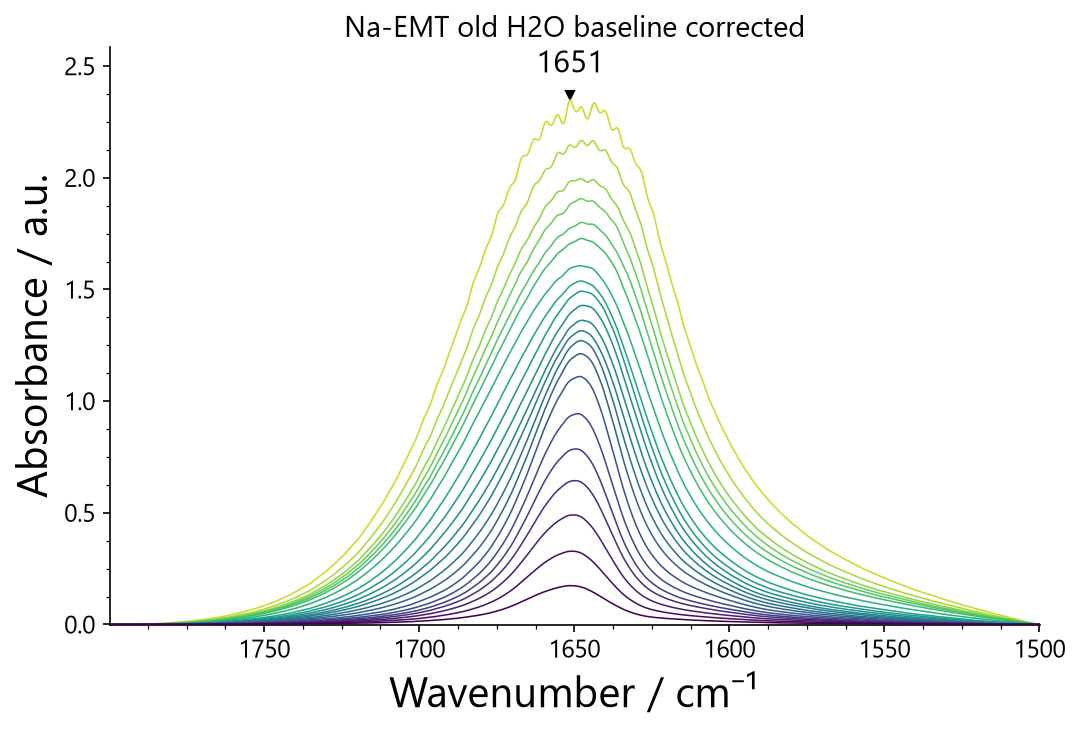

In [17]:
fig, ax = plt.subplots(figsize=(8, 5))
_ = D_Na_old_bending_corrected.plot(ax=ax, title="Na-EMT old H2O baseline corrected")

spectrum = D_Na_old_bending_corrected[-1]
peaks, props = spectrum.find_peaks(distance="5 cm^-1", prominence=0.1)

xs = np.asarray(peaks.x.data, dtype=float)
ys = np.asarray(peaks.data, dtype=float)

ax.plot(xs, ys + 0.01*ys, "v", color="black", markersize=4)
for x, y in zip(xs, ys):
    ax.annotate(f"{x:.0f}", (x, y), xytext=(0, 10), textcoords="offset points", rotation=0, va="bottom",
                ha="center", fontsize=15)

ax.set_ylim(np.min(D_Na_old_bending_corrected.data), np.max(D_Na_old_bending_corrected.data) + 0.1*np.max(D_Na_old_bending_corrected.data))
ax.set_xlabel("Wavenumber / cm⁻¹")
ax.set_ylabel("Absorbance / a.u.")
add_minor_ticks(ax)

fig.savefig(outputpath / "Na-EMT_old_H2O_corrected.svg", format="svg", bbox_inches="tight")

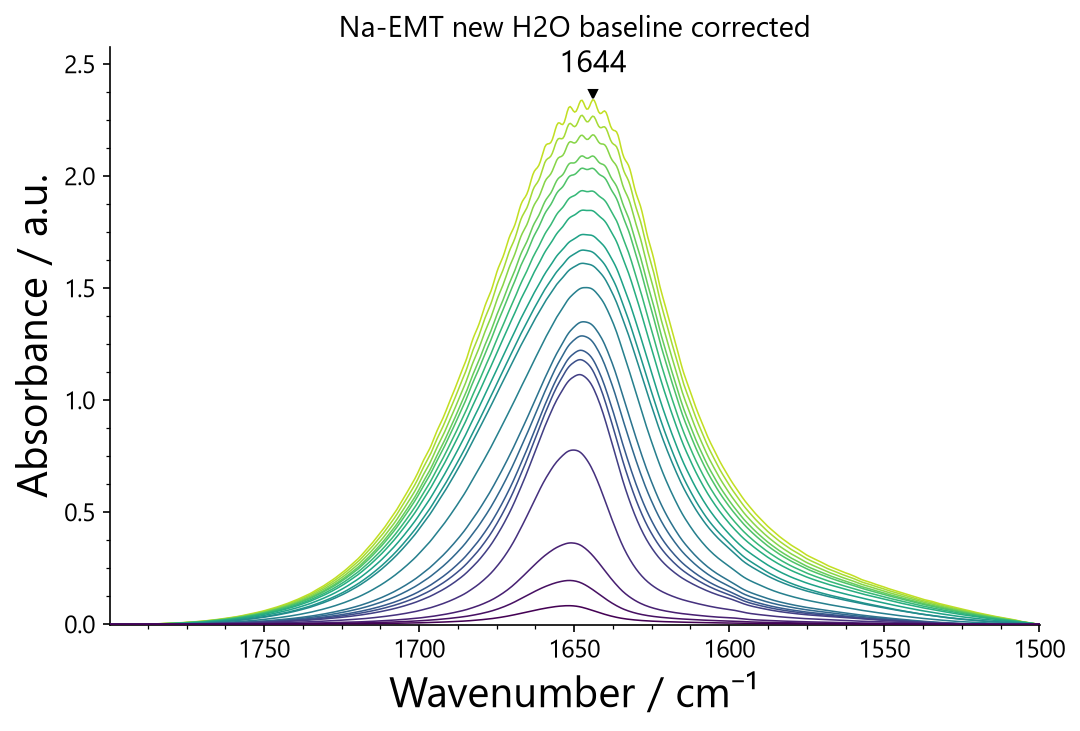

In [18]:
fig, ax = plt.subplots(figsize=(8, 5))
_ = D_Na_new_bending_corrected.plot(ax=ax, title="Na-EMT new H2O baseline corrected")

spectrum = D_Na_new_bending_corrected[-1]
peaks, props = spectrum.find_peaks(distance="5 cm^-1", prominence=0.1)

xs = np.asarray(peaks.x.data, dtype=float)
ys = np.asarray(peaks.data, dtype=float)

ax.plot(xs, ys + 0.01*ys, "v", color="black", markersize=4)
for x, y in zip(xs, ys):
    ax.annotate(f"{x:.0f}", (x, y), xytext=(0, 10), textcoords="offset points", rotation=0, va="bottom",
                ha="center", fontsize=15)

ax.set_ylim(np.min(D_Na_new_bending_corrected.data), np.max(D_Na_new_bending_corrected.data) + 0.1*np.max(D_Na_new_bending_corrected.data))
ax.set_xlabel("Wavenumber / cm⁻¹")
ax.set_ylabel("Absorbance / a.u.")
add_minor_ticks(ax)

fig.savefig(outputpath / "Na-EMT_new_H2O_corrected.svg", format="svg", bbox_inches="tight")

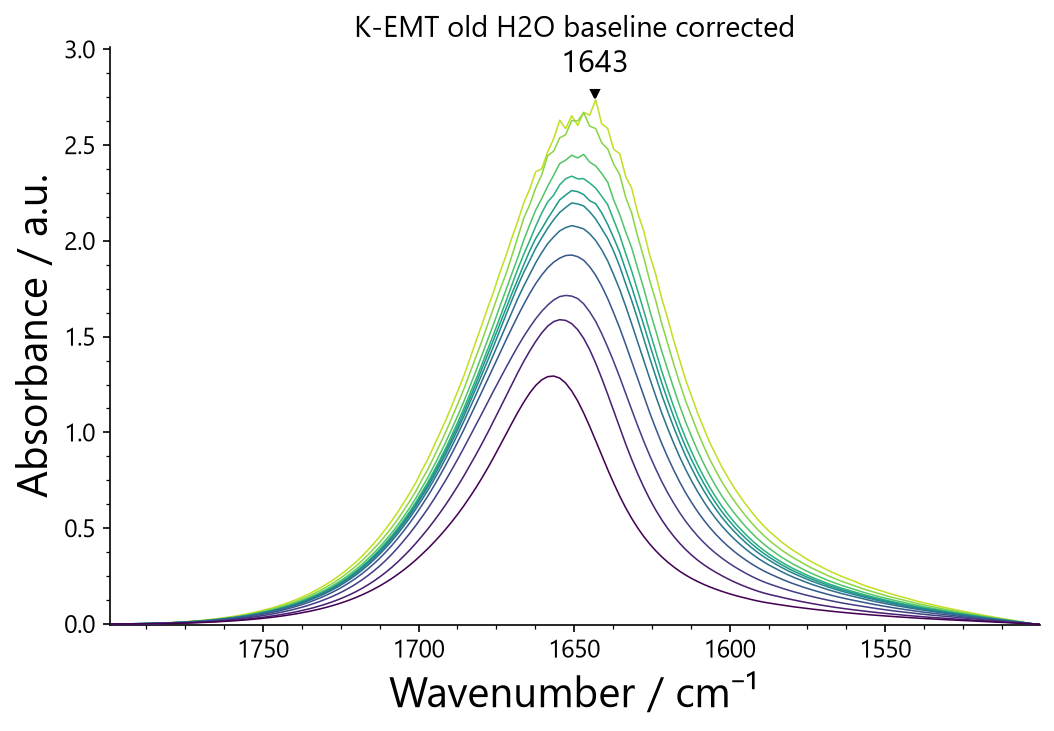

In [19]:
fig, ax = plt.subplots(figsize=(8, 5))
_ = D_K_old_bending_corrected.plot(ax=ax, title="K-EMT old H2O baseline corrected")

spectrum = D_K_old_bending_corrected[-1]
peaks, props = spectrum.find_peaks(distance="5 cm^-1", prominence=0.1)

xs = np.asarray(peaks.x.data, dtype=float)
ys = np.asarray(peaks.data, dtype=float)

ax.plot(xs, ys + 0.01*ys, "v", color="black", markersize=4)
for x, y in zip(xs, ys):
    ax.annotate(f"{x:.0f}", (x, y), xytext=(0, 10), textcoords="offset points", rotation=0, va="bottom",
                ha="center", fontsize=15)

ax.set_ylim(np.min(D_K_old_bending_corrected.data), np.max(D_K_old_bending_corrected.data) + 0.1*np.max(D_K_old_bending_corrected.data))
ax.set_xlabel("Wavenumber / cm⁻¹")
ax.set_ylabel("Absorbance / a.u.")
add_minor_ticks(ax)

fig.savefig(outputpath / "K-EMT_old_H2O_corrected.svg", format="svg", bbox_inches="tight")

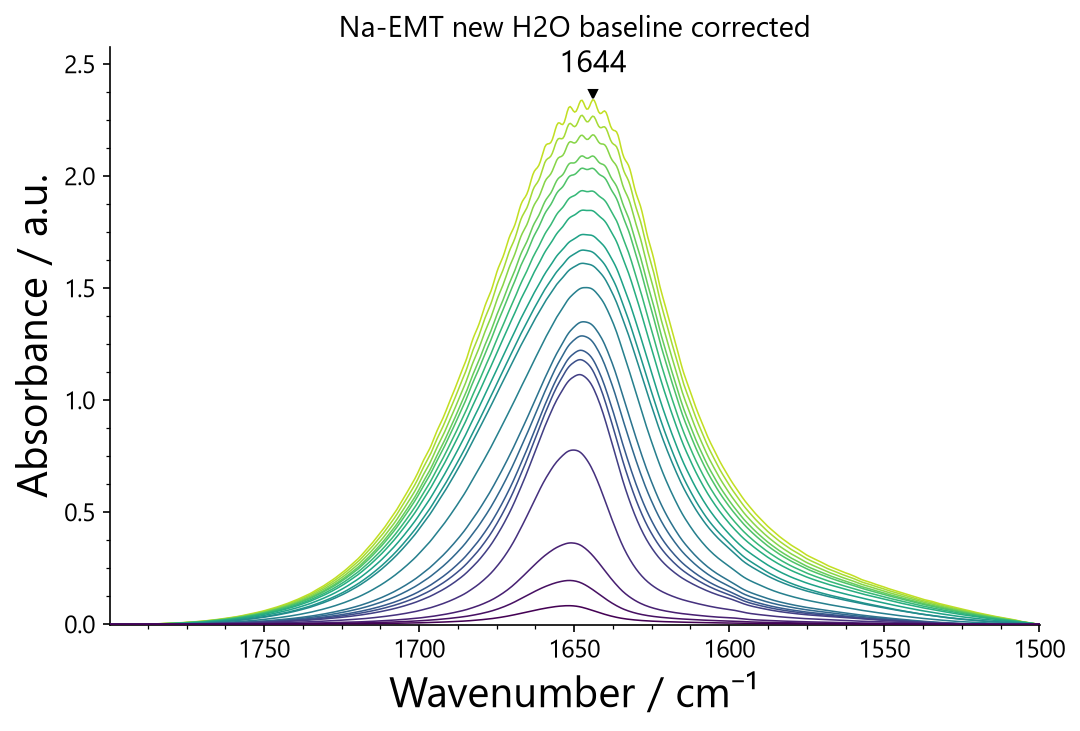

In [20]:
fig, ax = plt.subplots(figsize=(8, 5))
_ = D_Na_new_bending_corrected.plot(ax=ax, title="Na-EMT new H2O baseline corrected")

spectrum = D_Na_new_bending_corrected[-1]
peaks, props = spectrum.find_peaks(distance="5 cm^-1", prominence=0.1)

xs = np.asarray(peaks.x.data, dtype=float)
ys = np.asarray(peaks.data, dtype=float)

ax.plot(xs, ys + 0.01*ys, "v", color="black", markersize=4)
for x, y in zip(xs, ys):
    ax.annotate(f"{x:.0f}", (x, y), xytext=(0, 10), textcoords="offset points", rotation=0, va="bottom",
                ha="center", fontsize=15)

ax.set_ylim(np.min(D_Na_new_bending_corrected.data), np.max(D_Na_new_bending_corrected.data) + 0.1*np.max(D_Na_new_bending_corrected.data))
ax.set_xlabel("Wavenumber / cm⁻¹")
ax.set_ylabel("Absorbance / a.u.")
add_minor_ticks(ax)

fig.savefig(outputpath / "Na-EMT_new_H2O_corrected.svg", format="svg", bbox_inches="tight")

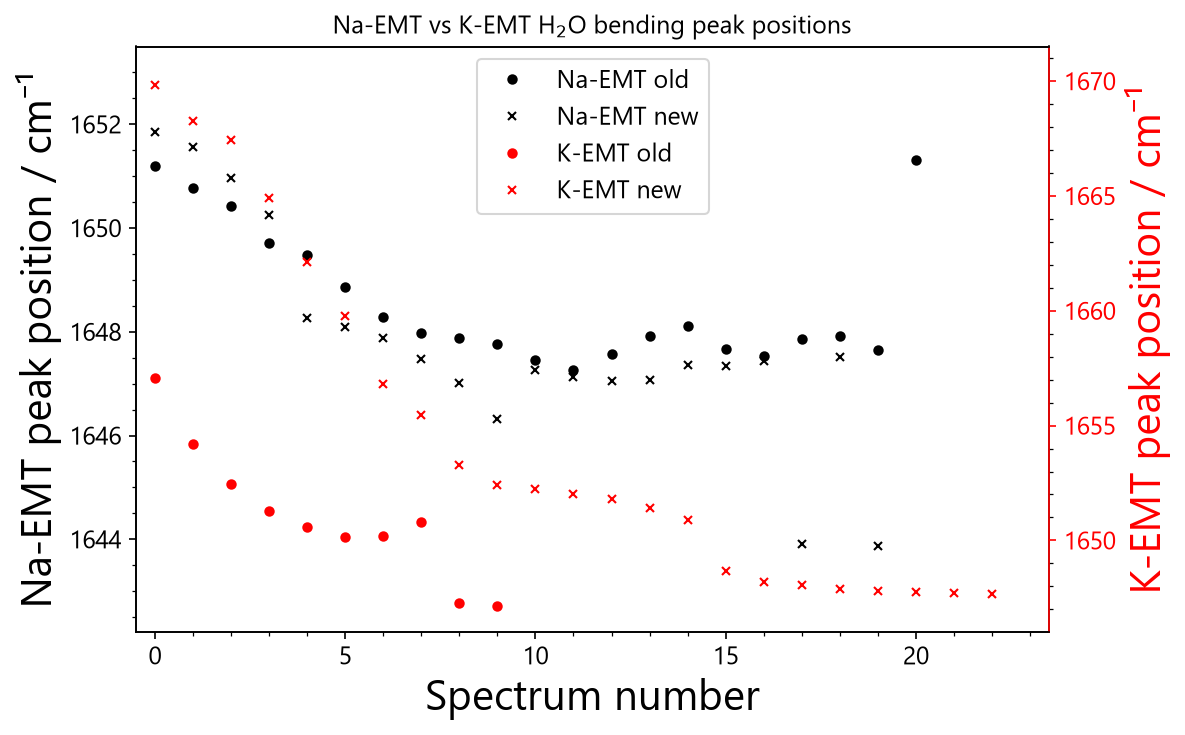

In [21]:
peaks_Na_old = []
for spectrum in D_Na_old_bending_corrected:
    peaks, props = spectrum.find_peaks(distance="5 cm^-1", prominence=0.1)
    peaks_Na_old.append(peaks.x.data)

peaks_Na_new = []
for spectrum in D_Na_new_bending_corrected:
    peaks, props = spectrum.find_peaks(distance="5 cm^-1", prominence=0.05)
    peaks_Na_new.append(peaks.x.data)

peaks_K_old = []
for spectrum in D_K_old_bending_corrected:
    peaks, props = spectrum.find_peaks(distance="5 cm^-1", prominence=0.1)
    peaks_K_old.append(peaks.x.data)

peaks_K_new = []
for spectrum in D_K_new_bending_corrected:
    peaks, props = spectrum.find_peaks(distance="5 cm^-1", prominence=0.05)
    peaks_K_new.append(peaks.x.data)

fig, ax = plt.subplots(figsize=(8, 5))
ax2 = ax.twinx()                                   # second y-axis, same x-axis

l1, = ax.plot(peaks_Na_old, marker="o", markersize=4, linestyle="", color="black", label="Na-EMT old")
l2, = ax.plot(peaks_Na_new, marker="x", markersize=4, linestyle="", color="black", label="Na-EMT new")
l3, = ax2.plot(peaks_K_old, marker="o", markersize=4, linestyle="", color="red", label="K-EMT old")
l4, = ax2.plot(peaks_K_new, marker="x", markersize=4, linestyle="", color="red", label="K-EMT new")

ax.set_xlabel("Spectrum number")
ax.set_xlim(-0.5, D_K_new.shape[0] + 0.5)
ax.set_ylim(np.min(peaks_Na_new) - 0.001*np.min(peaks_Na_new), np.max(peaks_Na_new) + 0.001*np.max(peaks_Na_new))
ax2.set_ylim(np.min(peaks_K_new) - 0.001*np.min(peaks_K_new), np.max(peaks_K_new) + 0.001*np.max(peaks_K_new))
ax.set_ylabel("Na-EMT peak position / cm\u207b\u00b9", color="black")
ax2.set_ylabel("K-EMT peak position / cm\u207b\u00b9", color="red")
ax.tick_params(axis="y", colors="black")
ax2.tick_params(axis="y", colors="red")
ax.set_title("Na-EMT vs K-EMT H$_2$O bending peak positions")

ax.legend(handles=[l1, l2, l3, l4], loc="upper center")            # one legend for both axes
ax2.spines["right"].set_visible(True)              # add_minor_ticks hides the right spine
ax2.spines["right"].set_color("red")
ax.minorticks_on()
ax2.minorticks_on()
fig.tight_layout()

In [22]:
area_Na_H2O_old = D_Na_old_bending_corrected.trapezoid(dim="x")
area_Na_H2O_new = D_Na_new_bending_corrected.trapezoid(dim="x")
area_K_H2O_old = D_K_old_bending_corrected.trapezoid(dim="x")
area_K_H2O_new = D_K_new_bending_corrected.trapezoid(dim="x")

N1        24.40 Pa   (unit used: torr)
N2        26.26 Pa   (unit used: torr)
N3        28.26 Pa   (unit used: torr)
N4        29.86 Pa   (unit used: torr)
N5        31.73 Pa   (unit used: torr)
N6        33.46 Pa   (unit used: torr)
N7        34.80 Pa   (unit used: torr)
N8        36.26 Pa   (unit used: torr)
N9        37.60 Pa   (unit used: torr)
N10       41.60 Pa   (unit used: torr)
N11       45.20 Pa   (unit used: torr)
N12       47.86 Pa   (unit used: torr)
N13       51.06 Pa   (unit used: torr)
N14       57.86 Pa   (unit used: torr)
N15       94.79 Pa   (unit used: torr)
N16      214.38 Pa   (unit used: torr)
N17      395.30 Pa   (unit used: torr)
N18      642.61 Pa   (unit used: torr)
N19      981.25 Pa   (unit used: torr)
N20     1649.19 Pa   (unit used: torr)
N21     2266.47 Pa   (unit used: torr)
N1         0.00 Pa   (unit used: torr)
N2         0.00 Pa   (unit used: torr)
N3         0.00 Pa   (unit used: torr)
N5         0.13 Pa   (unit used: torr)
N8         0.53 Pa   (uni

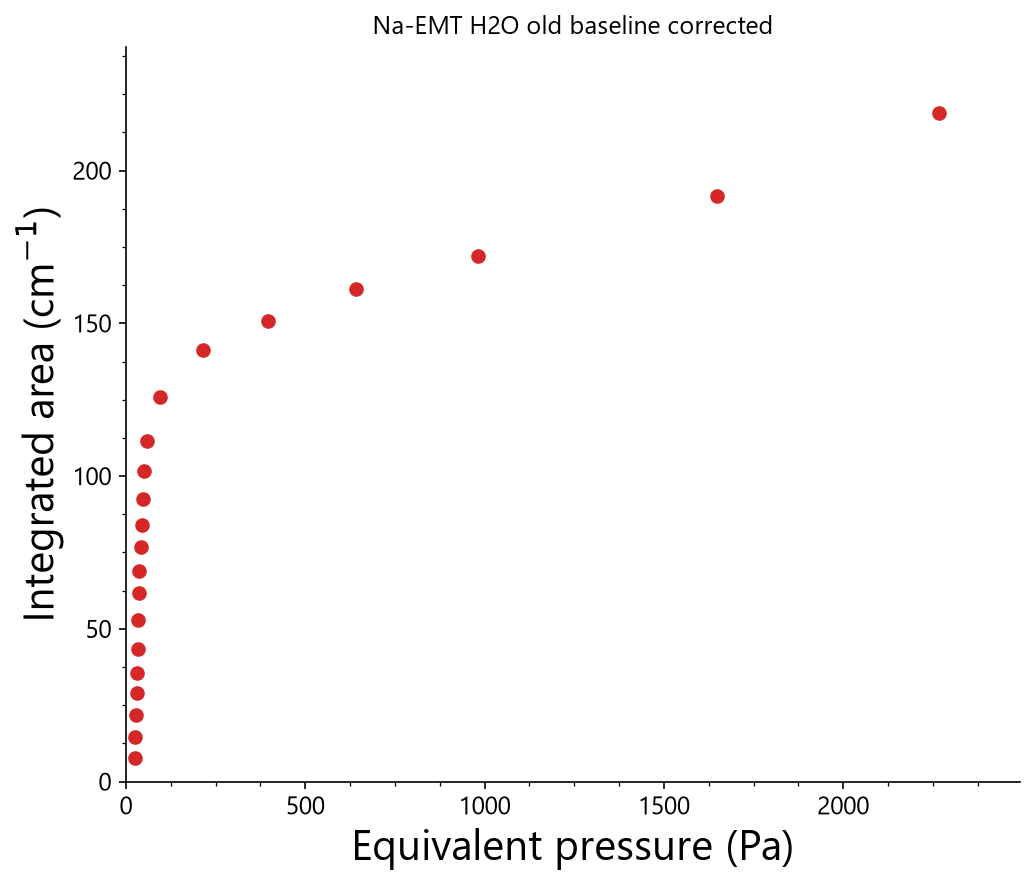

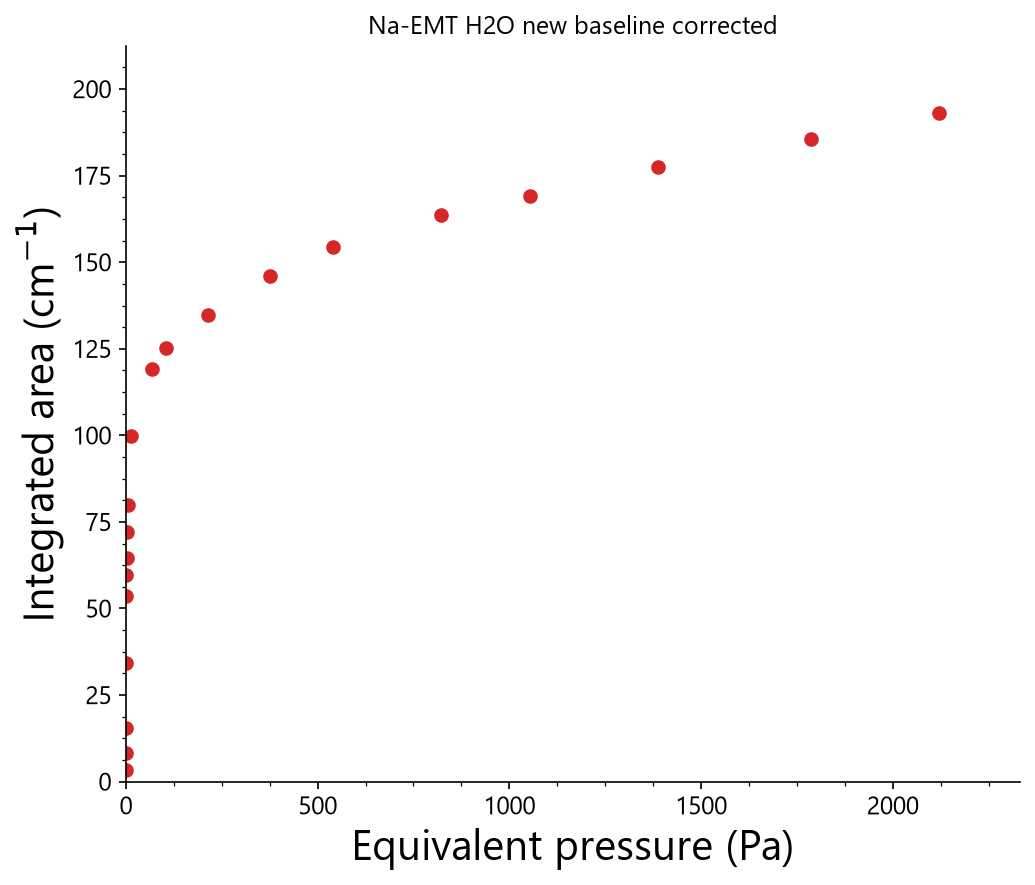

In [23]:
names_Na_old, x_Na_old = pressures_from_filenames(data_Na_old)
x_Na_old = x_Na_old[:len(area_Na_H2O_old.data)]  # truncate to match the number of spectra
y_Na_old = np.abs(np.asarray(area_Na_H2O_old.data)).ravel()

names_Na_new, x_Na_new = pressures_from_filenames(data_Na_new)
x_Na_new = x_Na_new[:len(area_Na_H2O_new.data)]  # truncate to match the number of spectra
y_Na_new = np.abs(np.asarray(area_Na_H2O_new.data)).ravel()

fig, ax1 = plt.subplots(1, 1, figsize=(7, 6))
ax1.plot(x_Na_old, y_Na_old, "o", color="C3")
ax1.set_ylabel(r"Integrated area (cm$^{-1}$)")
ax1.set_xlabel("Equivalent pressure (Pa)")
ax1.set_title(f"Na-EMT H2O old baseline corrected")
ax1.set_xlim(0, max(x_Na_old) + 0.1*max(x_Na_old))
ax1.set_ylim(0, max(y_Na_old) + 0.1*max(y_Na_old))
add_minor_ticks(ax1)
fig.tight_layout()
fig.savefig(outputpath / "Na-EMT-H2O_old_isotherm.svg", format="svg", bbox_inches="tight")
plt.show()

fig, ax1 = plt.subplots(1, 1, figsize=(7, 6))
ax1.plot(x_Na_new, y_Na_new, "o", color="C3")
ax1.set_ylabel(r"Integrated area (cm$^{-1}$)")
ax1.set_xlabel("Equivalent pressure (Pa)")
ax1.set_title(f"Na-EMT H2O new baseline corrected")
ax1.set_xlim(0, max(x_Na_new) + 0.1*max(x_Na_new))
ax1.set_ylim(0, max(y_Na_new) + 0.1*max(y_Na_new))
add_minor_ticks(ax1)
fig.tight_layout()
fig.savefig(outputpath / "Na-EMT-H2O_new _isotherm.svg", format="svg", bbox_inches="tight")
plt.show()

N1       152.60 Pa   (unit used: mbar)
N2       155.00 Pa   (unit used: mbar)
N3       173.20 Pa   (unit used: mbar)
N4       224.20 Pa   (unit used: mbar)
N5       322.50 Pa   (unit used: mbar)
N6       432.80 Pa   (unit used: mbar)
N7       509.00 Pa   (unit used: mbar)
N8       615.60 Pa   (unit used: mbar)
N9       944.00 Pa   (unit used: mbar)
N10     1550.00 Pa   (unit used: mbar)
N11     2260.00 Pa   (unit used: mbar)
N1         0.00 Pa   (unit used: torr)
N2         0.80 Pa   (unit used: torr)
N3         1.60 Pa   (unit used: torr)
N4         2.27 Pa   (unit used: torr)
N5         3.07 Pa   (unit used: torr)
N6         3.87 Pa   (unit used: torr)
N7         5.07 Pa   (unit used: torr)
N8         6.13 Pa   (unit used: torr)
N9        11.07 Pa   (unit used: torr)
N10       21.33 Pa   (unit used: torr)
N11       28.53 Pa   (unit used: torr)
N12       42.00 Pa   (unit used: torr)
N13       62.26 Pa   (unit used: torr)
N14      109.06 Pa   (unit used: torr)
N15      192.52 Pa   (uni

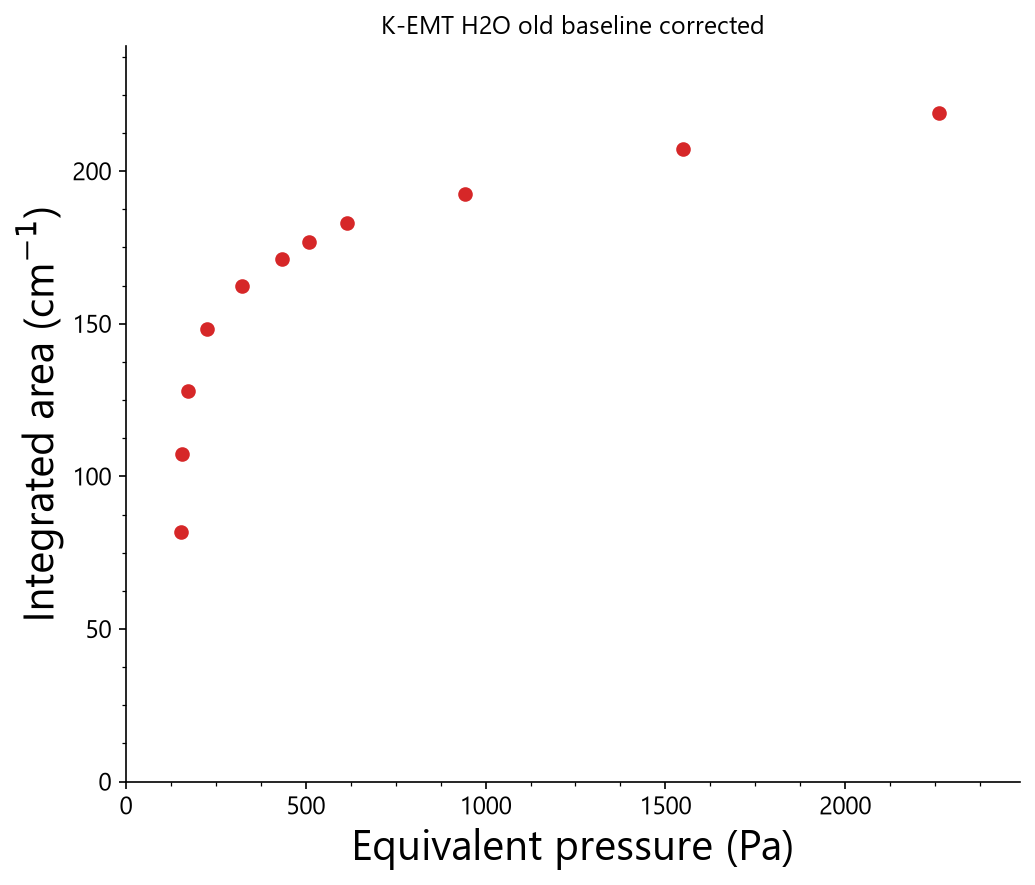

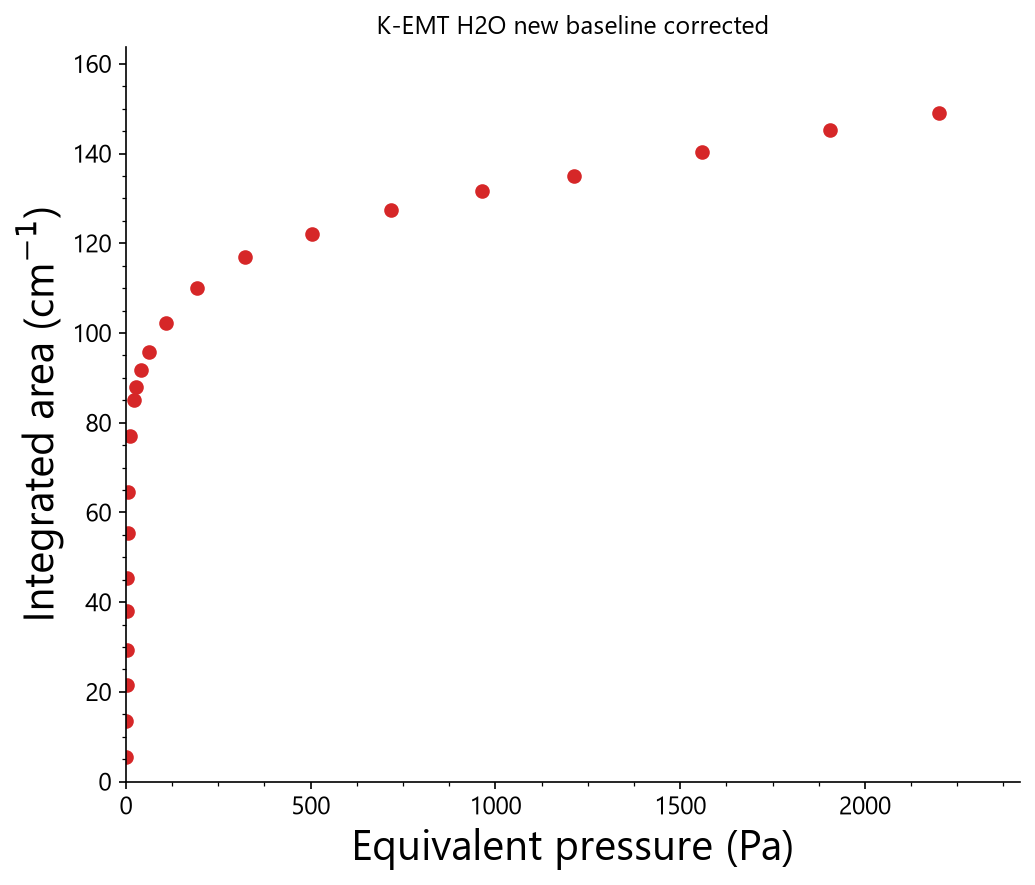

In [24]:
names_K_old, x_K_old = pressures_from_filenames(data_K_old)
x_K_old = x_K_old[:len(area_K_H2O_old.data)]  # truncate to match the number of spectra
y_K_old = np.abs(np.asarray(area_K_H2O_old.data)).ravel()

names_K_new, x_K_new = pressures_from_filenames(data_K_new)
x_K_new = x_K_new[:len(area_K_H2O_new.data)]  # truncate to match the number of spectra
y_K_new = np.abs(np.asarray(area_K_H2O_new.data)).ravel()

fig, ax1 = plt.subplots(1, 1, figsize=(7, 6))
ax1.plot(x_K_old, y_K_old, "o", color="C3")
ax1.set_ylabel(r"Integrated area (cm$^{-1}$)")
ax1.set_xlabel("Equivalent pressure (Pa)")
ax1.set_title(f"K-EMT H2O old baseline corrected")
ax1.set_xlim(0, max(x_K_old) + 0.1*max(x_K_old))
ax1.set_ylim(0, max(y_K_old) + 0.1*max(y_K_old))
add_minor_ticks(ax1)
fig.tight_layout()
fig.savefig(outputpath / "K-EMT-H2O_old_isotherm.svg", format="svg", bbox_inches="tight")
plt.show()

fig, ax1 = plt.subplots(1, 1, figsize=(7, 6))
ax1.plot(x_K_new, y_K_new, "o", color="C3")
ax1.set_ylabel(r"Integrated area (cm$^{-1}$)")
ax1.set_xlabel("Equivalent pressure (Pa)")
ax1.set_title(f"K-EMT H2O new baseline corrected")
ax1.set_xlim(0, max(x_K_new) + 0.1*max(x_K_new))
ax1.set_ylim(0, max(y_K_new) + 0.1*max(y_K_new))
add_minor_ticks(ax1)
fig.tight_layout()
fig.savefig(outputpath / "K-EMT-H2O_new _isotherm.svg", format="svg", bbox_inches="tight")
plt.show()

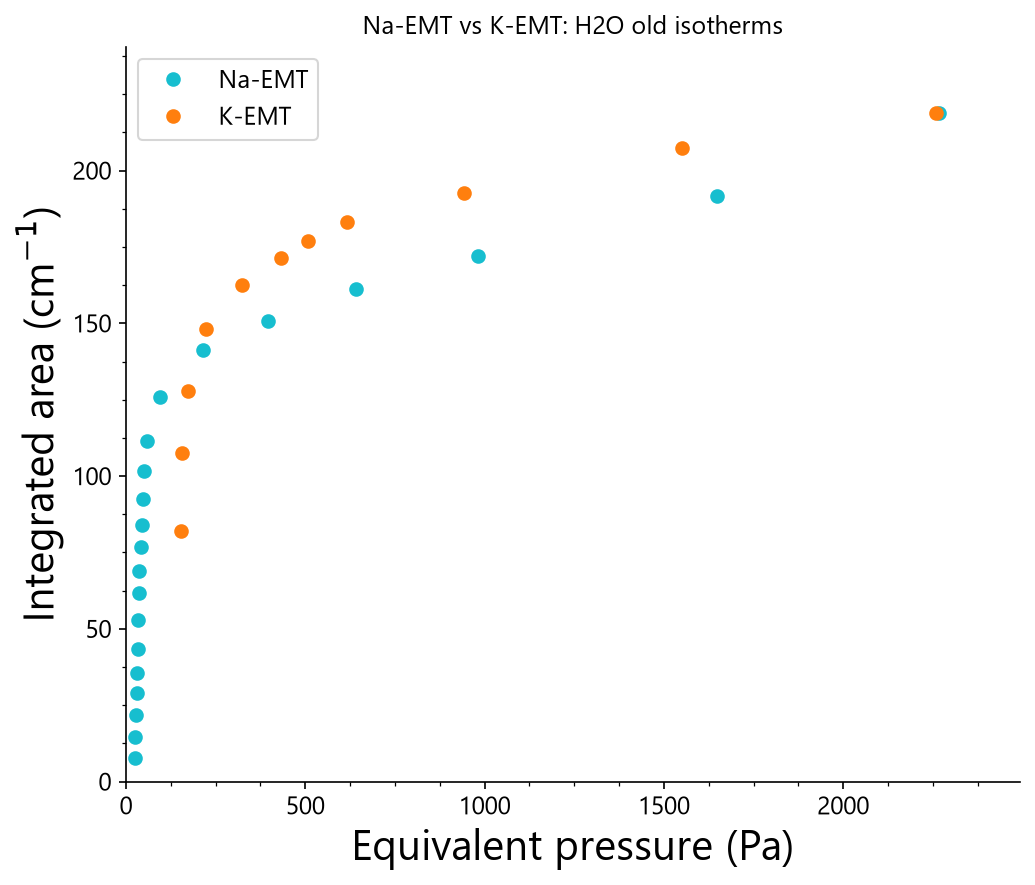

In [25]:
fig, ax = plt.subplots(1, 1, figsize=(7, 6))
ax.plot(x_Na_old, y_Na_old, "o", color="C9", label="Na-EMT")
ax.plot(x_K_old, y_K_old, "o", color="C1", label="K-EMT")
ax.set_ylabel(r"Integrated area (cm$^{-1}$)")
ax.set_xlabel("Equivalent pressure (Pa)")
ax.set_title(f"Na-EMT vs K-EMT: H2O old isotherms")
ax.set_xlim(0, max(x_Na_old) + 0.1*max(x_Na_old))
ax.set_ylim(0, max(y_Na_old) + 0.1*max(y_Na_old))
add_minor_ticks(ax)
ax.legend(loc="upper left")
add_minor_ticks(ax)
fig.tight_layout()
fig.savefig(outputpath / "Na-EMT_vs_K-EMT-H2O_old_isotherm.svg", format="svg", bbox_inches="tight")
plt.show()

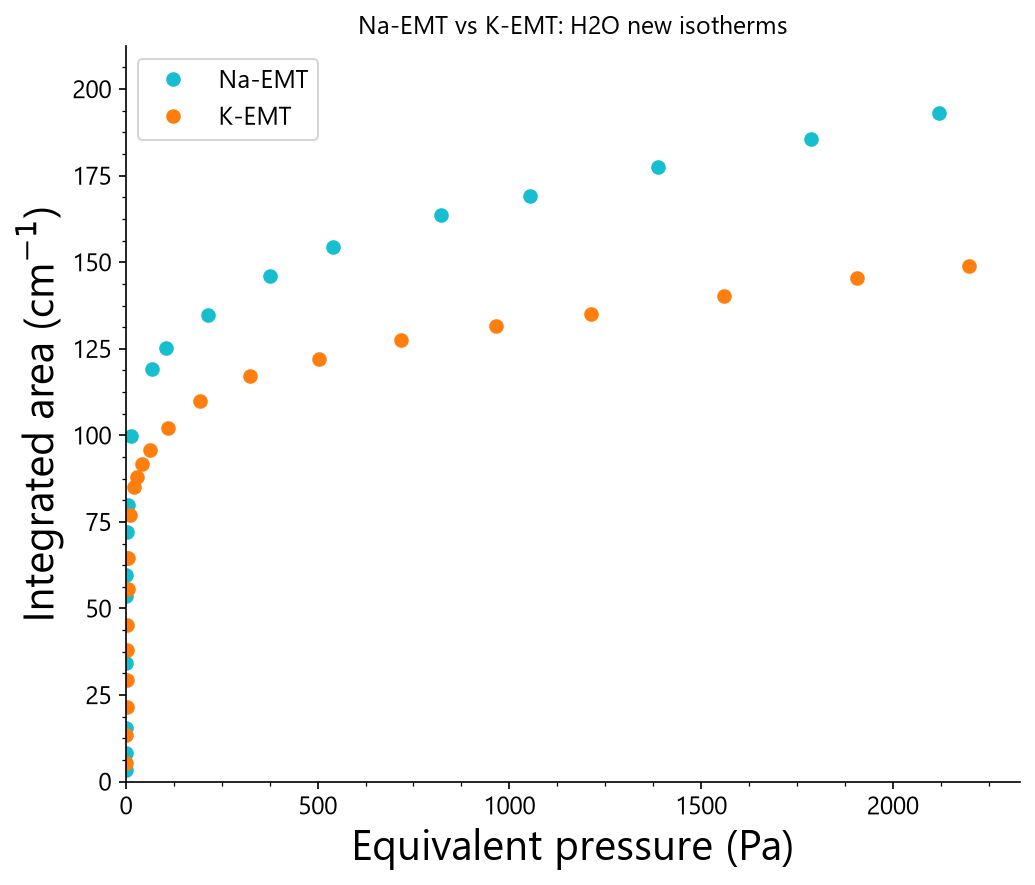

In [26]:
fig, ax = plt.subplots(1, 1, figsize=(7, 6))
ax.plot(x_Na_new, y_Na_new, "o", color="C9", label="Na-EMT")
ax.plot(x_K_new, y_K_new, "o", color="C1", label="K-EMT")
ax.set_ylabel(r"Integrated area (cm$^{-1}$)")
ax.set_xlabel("Equivalent pressure (Pa)")
ax.set_title(f"Na-EMT vs K-EMT: H2O new isotherms")
ax.set_xlim(0, max(x_Na_new) + 0.1*max(x_Na_new))
ax.set_ylim(0, max(y_Na_new) + 0.1*max(y_Na_new))
add_minor_ticks(ax)
ax.legend(loc="upper left")
add_minor_ticks(ax)
fig.tight_layout()
fig.savefig(outputpath / "Na-EMT_vs_K-EMT-H2O_new_isotherm.svg", format="svg", bbox_inches="tight")
plt.show()